# Riesgo de mercado del índice NASDAQ Composite en recesiones y expansiones de EE. UU.: evidencia estadística y evaluación de modelos de VaR y Expected Shortfall (1990-2026)

image.png

**Yamil Hugo Marzana Peralta** 


## 1. Comprensión del negocio

### 1.1 Planteamiento del problema y objetivos

**Problema.** Los modelos de riesgo de uso común suponen retornos normales o una volatilidad estable, y los retornos reales no cumplen ninguno de los dos supuestos. Si además el riesgo aumenta de forma sistemática en las recesiones, un modelo calibrado con datos tranquilos subestimará las pérdidas justo en las épocas de crisis.

**Pregunta principal.** ¿Difiere de forma estadísticamente significativa y relevante el riesgo diario del índice NASDAQ Composite entre meses de recesión y de expansión de EE. UU. (1990-2026), y qué modelo de Valor en Riesgo (VaR) y *Expected Shortfall* (ES) lo cuantifica mejor?

**Objetivo general.** Caracterizar y contrastar el riesgo diario del NASDAQ Composite entre recesiones y expansiones del NBER (1990-2026) y evaluar modelos de VaR y ES.

**Objetivos específicos.**
1. Documentar, auditar y preparar las series de FRED (`NASDAQCOM`, `VIXCLS` y `USREC`) en una base de trabajo reproducible.
2. Describir la distribución de los retornos y de la volatilidad, en conjunto y según el estado del ciclo.
3. Contrastar con pruebas paramétricas y no paramétricas la diferencia de riesgo entre recesión y expansión, y analizar su asociación con el VIX.
4. Estimar VaR y ES con tres modelos (histórico, normal y GJR-GARCH con distribución t) mediante ventana móvil.
5. Evaluar los modelos fuera de muestra con las pruebas de Kupiec y Christoffersen, y examinar si sus fallos se concentran en recesiones.

### 1.2 Preguntas secundarias

1. ¿Cómo se distribuyen los retornos diarios y cambia su forma entre recesión y expansión?
2. ¿Es mayor la volatilidad en recesión que en expansión, a escala mensual y diaria, y de qué magnitud?
3. ¿Se asocian el VIX del día anterior con la magnitud de los retornos, y el régimen de VIX con los días de pérdida?
4. ¿Qué modelos producen VaR y ES que superan el backtesting fuera de muestra?
5. ¿Se concentran en las recesiones las excepciones de esos modelos?

### 1.3 Criterios de éxito (fijados antes de ver resultados)

| # | Criterio | Regla |
|---|---|---|
| C1 | El riesgo difiere de forma significativa entre recesión y expansión | Sobre la log-volatilidad mensual: t de Welch y Mann-Whitney con p < 0.05 e IC 95 % de la diferencia sin el cero |
| C2 | La diferencia es de magnitud práctica relevante | Análisis de sensibilidad: razón de volatilidades recesión/expansión con IC 95 % (bootstrap de meses) frente a los umbrales 1.10, 1.25, 1.50 y 2.00. Un umbral se considera superado si el límite inferior del IC es mayor que él |
| C3 | Un modelo de VaR/ES es utilizable | No se rechazan Kupiec (95 % y 99 %) ni Christoffersen (independencia), con α = 0.05 |
| C4 | El modelo no falla de forma desproporcionada en recesión | Prueba binomial exacta: la proporción de excepciones en recesión es igual a la proporción de días de recesión |

Decisiones metodológicas relevantes: no se imputan datos faltantes; los valores atípicos se conservan (son los episodios de crisis); el análisis principal trata como expansión los meses recientes de `USREC` y se repite con la muestra recortada al 31-dic-2024 (robustez).

### 1.4 Importación de bibliotecas y parámetros fijados de antemano

**1.4.1 Descripción.** Se cargan las bibliotecas y se fijan los parámetros del análisis (nivel de significación, umbrales de C2, ventana móvil, fechas y semilla). Fijarlos aquí, antes de ver resultados, evita ajustarlos después según lo que se observe.

**1.4.2 Importar bibliotecas, definir parámetros y crear las carpetas de salida**

In [30]:
# 1.4.3 Código
print('▼ 1.4.4 Resultado')
import os, json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats, optimize
from scipy.special import gammaln, xlogy
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 150); pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.labelsize": 10, "figure.autolayout": True})
COL = {0: "#4C72B0", 1: "#C44E52"}          # 0 = expansión (azul), 1 = recesión (rojo)
NOMBRE = {0: "Expansión", 1: "Recesión"}

# --- Parámetros fijados de antemano ---
SEED = 20261109; rng = np.random.default_rng(SEED)
SERIES = ["NASDAQCOM", "VIXCLS", "USREC"]
FECHA_INI, FECHA_FIN, FECHA_DESCARGA = "1990-01-02", "2026-10-30", "2026-11-08"
ALPHA = 0.05                                  # nivel de significación
UMBRALES = [1.10, 1.25, 1.50, 2.00]           # rejilla de C2 (razón de volatilidades)
NIVELES, WINDOW, REFIT = [0.95, 0.99], 1000, 63   # backtesting: niveles, ventana móvil, reestimación GARCH
CORTE_ROBUSTEZ = "2024-12-31"                 # robustez (D13)
B_BOOT = 5000                                 # réplicas bootstrap
MIN_DIAS_MES = 10                             # días mínimos para calcular la volatilidad de un mes

# --- Fuentes de datos: 1) enlace de Google Drive; 2) carpeta 'datos' si el enlace no responde ---
DRIVE_ID = {"NASDAQCOM": "1vm5G-HFWRvJfJY-_Y2Rj2IB_dIdzdV2M",
            "USREC":     "1K1HX9K4kZM5RwkWVk23Emxzb9ALO0_gL",
            "VIXCLS":    "12AF-T55M_RPKeRnL9u2hnuXOLv1Yzliq"}
DATA_DIR = "datos"
FUENTE = {}                                   # de dónde se leyó cada serie

def leer_serie(nombre):
    """Lee una serie: primero desde Drive; si falla, desde datos/<nombre>.csv."""
    import io, urllib.request
    url = f"https://drive.google.com/uc?export=download&id={DRIVE_ID[nombre]}"
    try:
        with urllib.request.urlopen(url, timeout=20) as r:
            texto = r.read().decode("utf-8-sig")
        d = pd.read_csv(io.StringIO(texto))
        assert list(d.columns[:2]) == ["fecha", "valor"] and len(d) > 100   # descarta páginas HTML de error
        FUENTE[nombre] = "Google Drive"
        return d
    except Exception:
        ruta = os.path.join(DATA_DIR, f"{nombre}.csv")
        if not os.path.exists(ruta):
            raise FileNotFoundError(f"No se pudo leer {nombre}: el enlace de Drive no respondió y no existe {ruta}. "
                                    "Revise que el archivo de Drive esté compartido como 'Cualquier persona con el enlace'.")
        FUENTE[nombre] = ruta
        return pd.read_csv(ruta)

FIG_DIR, RES_DIR = "figuras", "resultados"
for d in (FIG_DIR, RES_DIR): os.makedirs(d, exist_ok=True)
RES = {}                                      # métricas que se reutilizan más adelante
NFIG = [0]

def guardar(nombre):
    """Guarda la figura actual (PNG, 200 dpi) y la muestra."""
    plt.savefig(os.path.join(FIG_DIR, nombre), dpi=200, bbox_inches="tight"); plt.show()

def p_fmt(p):
    return "< 0.001" if p < 0.001 else f"{p:.3f}"

print("Semilla:", SEED)
print("Parámetros:", dict(ALPHA=ALPHA, UMBRALES=UMBRALES, NIVELES=NIVELES, WINDOW=WINDOW, REFIT=REFIT, CORTE_ROBUSTEZ=CORTE_ROBUSTEZ, B_BOOT=B_BOOT))

▼ 1.4.4 Resultado
Semilla: 20261109
Parámetros: {'ALPHA': 0.05, 'UMBRALES': [1.1, 1.25, 1.5, 2.0], 'NIVELES': [0.95, 0.99], 'WINDOW': 1000, 'REFIT': 63, 'CORTE_ROBUSTEZ': '2024-12-31', 'B_BOOT': 5000}


**1.4.5 Interpretación.** Quedan fijados los parámetros antes de ver resultados: α = 0.05, umbrales 1.10, 1.25, 1.50 y 2.00, ventana de 1,000 días y semilla 20261109. El notebook busca los CSV en `datos` o en `fred_individuales`, de modo que se puede ejecutar de principio a fin en otro equipo con los mismos archivos.

## 2. Comprensión de los datos

### 2.1 Carga e inspección de los datos

**2.1.1 Descripción.** Se cargan los tres CSV descargados de FRED con la biblioteca `fredapi` el 8 de noviembre de 2026 (valores vigentes ese día). Se leen desde Google Drive y, si el enlace no responde, desde la carpeta `datos/`. Los originales no se modifican: se guardan en `crudo` y todo el trabajo posterior se hace sobre copias. Se revisan las primeras y últimas observaciones, la forma de cada tabla y los tipos de las columnas.

**Procedencia y descarga de los datos.-** Las tres series provienen de FRED (Federal Reserve Bank of St. Louis) y se descargaron el 8 de noviembre de 2026 con la biblioteca fredapi (https://fred.stlouisfed.org/docs/api/fred/), del 2 de enero de 1990 al 30 de octubre de 2026: NASDAQCOM (cierre diario del NASDAQ Composite), VIXCLS (cierre diario del índice VIX) y USREC (indicador mensual de recesiones del NBER). Cada serie quedó guardada en un CSV con las columnas fecha y valor. Este notebook no descarga datos: lee esos CSV desde Google Drive (o desde la carpeta datos/). Se eligieron estas series porque cubren los tres elementos de la pregunta: el activo (NASDAQ), el estado del ciclo (USREC) y la volatilidad esperada (VIX).


**2.1.2 Cargar los CSV originales, mostrar primeras y últimas filas, dimensiones y tipos**

In [31]:
# 2.1.3 Código
print('▼ 2.1.4 Resultado')
crudo = {s: leer_serie(s) for s in SERIES}   # originales (no se tocan)
print("Fuente de cada serie:", FUENTE)
for s, d in crudo.items():
    print(f"\n== {s}: {d.shape[0]} filas x {d.shape[1]} columnas | tipos: {dict(d.dtypes.astype(str))}")
    display(pd.concat([d.head(3), d.tail(3)]))
trab = {s: d.copy() for s, d in crudo.items()}     # copias de trabajo
for s in SERIES: trab[s]["fecha"] = pd.to_datetime(trab[s]["fecha"])   # fecha -> datetime
print("\nRangos de fechas:", {s: (trab[s].fecha.min().date().isoformat(), trab[s].fecha.max().date().isoformat()) for s in SERIES})

▼ 2.1.4 Resultado
Fuente de cada serie: {'NASDAQCOM': 'Google Drive', 'VIXCLS': 'Google Drive', 'USREC': 'Google Drive'}

== NASDAQCOM: 9608 filas x 2 columnas | tipos: {'fecha': 'object', 'valor': 'float64'}


,fecha,valor
0,1990-01-02,459.33
1,1990-01-03,460.90
2,1990-01-04,459.39
9605,2026-10-28,26549.85
9606,2026-10-29,26184.72
9607,2026-10-30,25437.00



== VIXCLS: 9609 filas x 2 columnas | tipos: {'fecha': 'object', 'valor': 'float64'}


,fecha,valor
0,1990-01-02,17.24
1,1990-01-03,18.19
2,1990-01-04,19.22
9606,2026-10-28,16.91
9607,2026-10-29,17.20
9608,2026-10-30,19.42



== USREC: 442 filas x 2 columnas | tipos: {'fecha': 'object', 'valor': 'float64'}


,fecha,valor
0,1990-01-01,0.0
1,1990-02-01,0.0
2,1990-03-01,0.0
439,2026-08-01,0.0
440,2026-09-01,0.0
441,2026-10-01,0.0



Rangos de fechas: {'NASDAQCOM': ('1990-01-02', '2026-10-30'), 'VIXCLS': ('1990-01-02', '2026-10-30'), 'USREC': ('1990-01-01', '2026-10-01')}


**2.1.5 Interpretación.** Las tres tablas tienen dos columnas (`fecha` y `valor`). NASDAQCOM tiene 9,608 filas diarias del 2-ene-1990 al 30-oct-2026, con el índice pasando de 459.33 a 25,437.00 puntos. VIXCLS tiene 9,609 filas diarias en el mismo rango. USREC tiene 442 filas mensuales (enero de 1990 a octubre de 2026). Las fechas llegan como texto y se convierten a fecha en la copia de trabajo; los originales no se tocan. Las celdas vacías corresponden a días sin dato (feriados), que FRED marca con un punto.

### 2.2 Diccionario de variables

**2.2.1 Descripción.** Se documenta cada variable usada: nombre original, definición, tipo, escala de medición, unidades o códigos y función en el análisis. Se distinguen las variables originales de las derivadas y se separan las nominales, ordinales y cuantitativas.

**2.2.2 Construir y guardar el diccionario de variables**

In [32]:
# 2.2.3 Código
print('▼ 2.2.4 Resultado')
dic = pd.DataFrame([
 ["fecha (NASDAQCOM, VIXCLS)", "Fecha de la observación (día de negociación)", "Fecha", "Intervalo (calendario)", "AAAA-MM-DD", "Identificador"],
 ["fecha (USREC)", "Primer día del mes al que se refiere el indicador", "Fecha", "Intervalo (calendario)", "AAAA-MM-01", "Identificador"],
 ["valor (NASDAQCOM)", "Nivel de cierre del índice NASDAQ Composite (base 100 el 5-feb-1971)", "Cuantitativa continua", "Razón", "Puntos del índice", "Insumo de los retornos"],
 ["valor (VIXCLS)", "Índice de volatilidad VIX (volatilidad implícita a 30 días de opciones sobre el S&P 500)", "Cuantitativa continua", "Razón", "Puntos porcentuales anualizados", "Explicativa"],
 ["valor (USREC)", "Indicador NBER de recesión: 1 desde el mes siguiente al pico hasta el mes del valle", "Binaria (nominal)", "Nominal", "0 = expansión, 1 = recesión", "Agrupación"],
 ["ret (derivada)", "Retorno logarítmico diario = 100 x ln(P_t / P_t-1)", "Cuantitativa continua", "Intervalo", "% diario", "Resultado"],
 ["abs_ret (derivada)", "Magnitud del retorno = |ret|", "Cuantitativa continua", "Razón", "% diario", "Resultado (medida de riesgo)"],
 ["dia_baja (derivada)", "1 si ret < 0, 0 en otro caso", "Binaria (nominal)", "Nominal", "0 = no, 1 = sí", "Resultado"],
 ["rec (derivada)", "Estado del ciclo del mes del día, tomado de USREC", "Binaria (nominal)", "Nominal", "0 = expansión, 1 = recesión", "Agrupación"],
 ["vix_lag (derivada)", "VIX del día de negociación anterior", "Cuantitativa continua", "Razón", "Puntos porcentuales", "Explicativa"],
 ["dvix (derivada)", "Cambio del VIX respecto al día anterior = VIX_t - VIX_t-1", "Cuantitativa continua", "Intervalo", "Puntos", "Explicativa"],
 ["regimen_vix (derivada)", "Tercil del VIX del día anterior (bajo, medio, alto)", "Ordinal", "Ordinal", "bajo < medio < alto", "Agrupación"],
 ["logvol (derivada, mensual)", "Logaritmo de la desviación estándar de los retornos diarios del mes", "Cuantitativa continua", "Intervalo", "ln(% diario)", "Resultado de C1"],
], columns=["Variable", "Definición", "Tipo", "Escala", "Categorías / unidades", "Función"])
display(dic); dic.to_csv(os.path.join(RES_DIR, "diccionario_variables.csv"), index=False)
print("\nUnidad de análisis: un día de negociación del NASDAQ (la comparación de C1 usa el mes como unidad).")
print("Procedencia: FRED (Federal Reserve Bank of St. Louis) vía fredapi; fuentes originales: Nasdaq, CBOE y NBER.")

▼ 2.2.4 Resultado


,Variable,Definición,Tipo,Escala,Categorías / unidades,Función
0,"fecha (NASDAQCOM, VIXCLS)",Fecha de la observación (día de negociación),Fecha,Intervalo (calendario),AAAA-MM-DD,Identificador
1,fecha (USREC),Primer día del mes al que se refiere el indicador,Fecha,Intervalo (calendario),AAAA-MM-01,Identificador
2,valor (NASDAQCOM),Nivel de cierre del índice NASDAQ Composite (b...,Cuantitativa continua,Razón,Puntos del índice,Insumo de los retornos
3,valor (VIXCLS),Índice de volatilidad VIX (volatilidad implíci...,Cuantitativa continua,Razón,Puntos porcentuales anualizados,Explicativa
4,valor (USREC),Indicador NBER de recesión: 1 desde el mes sig...,Binaria (nominal),Nominal,"0 = expansión, 1 = recesión",Agrupación
5,ret (derivada),Retorno logarítmico diario = 100 x ln(P_t / P_...,Cuantitativa continua,Intervalo,% diario,Resultado
6,abs_ret (derivada),Magnitud del retorno = |ret|,Cuantitativa continua,Razón,% diario,Resultado (medida de riesgo)
7,dia_baja (derivada),"1 si ret < 0, 0 en otro caso",Binaria (nominal),Nominal,"0 = no, 1 = sí",Resultado
8,rec (derivada),"Estado del ciclo del mes del día, tomado de USREC",Binaria (nominal),Nominal,"0 = expansión, 1 = recesión",Agrupación
9,vix_lag (derivada),VIX del día de negociación anterior,Cuantitativa continua,Razón,Puntos porcentuales,Explicativa



Unidad de análisis: un día de negociación del NASDAQ (la comparación de C1 usa el mes como unidad).
Procedencia: FRED (Federal Reserve Bank of St. Louis) vía fredapi; fuentes originales: Nasdaq, CBOE y NBER.


**2.2.5 Interpretación.** El diccionario distingue las variables nominales (estado del ciclo, día de baja), la ordinal (régimen de VIX) y las cuantitativas (retorno, VIX, volatilidad). El código 0/1 de `USREC` es una etiqueta de categoría, no una cantidad: "1" no significa "el doble" de "0". El régimen de VIX es ordinal: ordena los días, pero la distancia entre bajo, medio y alto no es una cantidad.

### 2.3 Auditoría de calidad: faltantes, duplicados y consistencia

**2.3.1 Descripción.** Se mide la cantidad y el porcentaje de valores faltantes por serie, se buscan fechas duplicadas, se verifican rangos y códigos y se comparan las fechas de NASDAQCOM y VIXCLS. Solo se diagnostica: las decisiones se toman y se registran en la sección 3.

**2.3.2 Diagnosticar faltantes, duplicados, rangos y coincidencia de fechas**

In [33]:
# 2.3.3 Código
print('▼ 2.3.4 Resultado')
aud = []
for s in SERIES:
    d = trab[s]; n = len(d); nf = int(d["valor"].isna().sum())
    aud.append([s, n, nf, round(100 * nf / n, 2), int(d["fecha"].duplicated().sum()), d["valor"].min(), d["valor"].max(), bool(d["fecha"].is_monotonic_increasing)])
aud = pd.DataFrame(aud, columns=["serie", "filas", "faltantes", "% faltantes", "fechas duplicadas", "mínimo", "máximo", "fechas ordenadas"])
display(aud)

fn = set(trab["NASDAQCOM"].dropna(subset=["valor"]).fecha); fv = set(trab["VIXCLS"].dropna(subset=["valor"]).fecha)
todas_n, todas_v = set(trab["NASDAQCOM"].fecha), set(trab["VIXCLS"].fecha)
print("Fechas con NASDAQ y sin VIX:", len(fn - fv), "| con VIX y sin NASDAQ:", len(fv - fn))
print("Fechas presentes solo en VIXCLS (fila inexistente en NASDAQCOM):", sorted(d.date().isoformat() for d in todas_v - todas_n))
print("Valores distintos de USREC:", [float(x) for x in sorted(trab["USREC"]["valor"].unique())], "| meses:", len(trab["USREC"]), "| todos día 1:", bool((trab["USREC"].fecha.dt.day == 1).all()))
print("Meses de recesión en USREC:", int(trab["USREC"]["valor"].sum()), f"({100 * trab['USREC']['valor'].mean():.1f} %) | último mes:", trab["USREC"].fecha.max().date())
inicio_rec = trab["USREC"].loc[trab["USREC"].valor.diff().fillna(trab["USREC"].valor) == 1, "fecha"].dt.strftime("%Y-%m").tolist()
fin_rec = trab["USREC"].loc[trab["USREC"].valor.diff().shift(-1).fillna(0) == -1, "fecha"].dt.strftime("%Y-%m").tolist()
print("Episodios de recesión (primer y último mes):", list(zip(inicio_rec, fin_rec)))
RES["meses_rec_usrec"] = int(trab["USREC"]["valor"].sum())

▼ 2.3.4 Resultado


,serie,filas,faltantes,% faltantes,fechas duplicadas,mínimo,máximo,fechas ordenadas
0,NASDAQCOM,9608,331,3.45,0,325.44,27599.89,True
1,VIXCLS,9609,302,3.14,0,9.14,82.69,True
2,USREC,442,0,0.00,0,0.00,1.00,True


Fechas con NASDAQ y sin VIX: 4 | con VIX y sin NASDAQ: 34
Fechas presentes solo en VIXCLS (fila inexistente en NASDAQCOM): ['2026-09-07']
Valores distintos de USREC: [0.0, 1.0] | meses: 442 | todos día 1: True
Meses de recesión en USREC: 36 (8.1 %) | último mes: 2026-10-01
Episodios de recesión (primer y último mes): [('1990-08', '1991-03'), ('2001-04', '2001-11'), ('2008-01', '2009-06'), ('2020-03', '2020-04')]


**2.3.5 Interpretación.** No hay fechas duplicadas ni valores fuera de rango (NASDAQCOM: 325.44 a 27,599.89; VIX: 9.14 a 82.69; USREC solo toma 0 y 1). Faltan 331 valores de NASDAQCOM (3.45 %) y 302 de VIXCLS (3.14 %), casi todos feriados. Las series no coinciden del todo: hay 4 días con NASDAQ y sin VIX, 34 con VIX y sin NASDAQ, y una fecha (7-sep-2026, feriado en EE. UU.) que solo existe en VIXCLS. USREC suma 36 meses de recesión (8.1 %) en cuatro episodios que coinciden con las fechas del NBER: ago-1990 a mar-1991, abr a nov de 2001, ene-2008 a jun-2009 y mar a abr de 2020. No hay ninguna recesión posterior a 2020.

## 3. Preparación de los datos (y exploración descriptiva)

### 3.1 Alineación de las series y construcción de variables

**3.1.1 Descripción.** Se unen las series por fecha sin imputar nada. Se conservan solo los días en que el NASDAQ cerró, se calculan los retornos logarítmicos entre cierres consecutivos y se asigna a cada día el estado del ciclo de su mes (`USREC` es mensual). El VIX del día anterior se toma de la fila previa de negociación. El régimen de VIX se define con los terciles de la muestra completa (con la limitación de que usa información de toda la muestra; no interviene en el backtesting).

**3.1.2 Unir las series y crear retornos, estado del ciclo, VIX rezagado y régimen de VIX**

In [34]:
# 3.1.3 Código
print('▼ 3.1.4 Resultado')
n_ = trab["NASDAQCOM"].set_index("fecha")["valor"].rename("nasdaq")
v_ = trab["VIXCLS"].set_index("fecha")["valor"].rename("vix")
base = pd.concat([n_, v_], axis=1, sort=True)                 # unión de fechas, sin rellenar
dias = base[base["nasdaq"].notna()].copy()                    # solo días con cierre del NASDAQ
dias["ret"] = 100 * np.log(dias["nasdaq"]).diff()             # retorno log (%) entre cierres consecutivos
dias["gap"] = dias.index.to_series().diff().dt.days           # días de calendario desde el cierre anterior
dias["cruza_feriado"] = dias["gap"] > 3                       # el retorno abarca más de un día hábil
usrec = trab["USREC"].set_index("fecha")["valor"].astype(int)
dias["rec"] = usrec.reindex(dias.index.to_period("M").to_timestamp()).to_numpy()   # estado del mes
assert dias["rec"].notna().all()
dias["rec"] = dias["rec"].astype(int)
dias["vix_lag"] = dias["vix"].shift(1)                        # VIX del día de negociación anterior
dias["dvix"] = dias["vix"] - dias["vix_lag"]                  # cambio del VIX
work = dias.dropna(subset=["ret"]).copy()                     # se pierde la primera fila (sin retorno)
work["abs_ret"] = work["ret"].abs()
work["dia_baja"] = (work["ret"] < 0).astype(int)
work["regimen_vix"] = pd.qcut(work["vix_lag"], 3, labels=["bajo", "medio", "alto"])   # terciles (ordinal)
cortes = work["vix_lag"].quantile([1/3, 2/3]).round(2).tolist()

tam = pd.DataFrame([
  ["Filas en la unión de fechas", len(base)],
  ["Días con cierre del NASDAQ", len(dias)],
  ["Retornos (se pierde el primer día)", len(work)],
  ["Retornos con VIX del día y del día anterior (para dvix)", int(work["dvix"].notna().sum())],
  ["Retornos con VIX del día anterior (para vix_lag y régimen)", int(work["vix_lag"].notna().sum())],
], columns=["Etapa", "Observaciones"])
display(tam)
print("Cortes de los terciles del VIX rezagado:", cortes, "| retornos que cruzan feriado (>3 días de calendario):", int(work["cruza_feriado"].sum()), "| retornos exactamente 0:", int((work["ret"] == 0).sum()))
RES.update(n_ret=len(work), n_vix=int(work["vix_lag"].notna().sum()), cortes_vix=cortes)

▼ 3.1.4 Resultado


,Etapa,Observaciones
0,Filas en la unión de fechas,9609
1,Días con cierre del NASDAQ,9277
2,Retornos (se pierde el primer día),9276
3,Retornos con VIX del día y del día anterior (p...,9268
4,Retornos con VIX del día anterior (para vix_la...,9272


Cortes de los terciles del VIX rezagado: [15.21, 20.74] | retornos que cruzan feriado (>3 días de calendario): 238 | retornos exactamente 0: 2


**3.1.5 Interpretación.** La unión tiene 9,609 fechas; 9,277 tienen cierre del NASDAQ y producen 9,276 retornos. Para los análisis con el VIX del día anterior quedan 9,272 retornos, y 9,268 con el cambio del VIX del día. Los terciles del VIX rezagado cortan en 15.21 y 20.74 puntos. 238 retornos cruzan un feriado y se conservan marcados. Solo 2 retornos son exactamente 0, por lo que la definición de día de baja (retorno < 0) deja prácticamente iguales los grupos "sube" y "no baja".

### 3.2 Verificación de las variables derivadas

**3.2.1 Descripción.** Se comprueba a mano que el retorno logarítmico se calculó bien, que cada mes tiene un único estado y que los días de recesión se reparten en los episodios esperados.

**3.2.2 Verificar los retornos con un cálculo manual y contar días por estado y por episodio**

In [35]:
# 3.2.3 Código
print('▼ 3.2.4 Resultado')
fila = work.iloc[100]; previo = dias.loc[:fila.name].iloc[-2]
manual = 100 * (np.log(fila["nasdaq"]) - np.log(previo["nasdaq"]))
print(f"Chequeo {fila.name.date()}: precio {fila['nasdaq']} vs {previo['nasdaq']} -> retorno manual {manual:.4f} | en la base {fila['ret']:.4f}")
assert abs(manual - fila["ret"]) < 1e-9
print("Meses con más de un estado:", int((work.groupby(work.index.to_period('M'))['rec'].nunique() > 1).sum()))
ep = work[work["rec"] == 1].copy(); ep["episodio"] = (ep.index.to_series().diff().dt.days > 40).cumsum()
display(ep.groupby("episodio").agg(inicio=("ret", lambda s: s.index.min().date()), fin=("ret", lambda s: s.index.max().date()), dias=("ret", "size")))
print(f"Días de recesión: {int(work['rec'].sum())} de {len(work)} ({100 * work['rec'].mean():.1f} %)")
RES.update(dias_rec=int(work["rec"].sum()), pct_dias_rec=100 * work["rec"].mean())
display(work[["nasdaq", "vix", "ret", "rec", "vix_lag", "dvix", "abs_ret", "dia_baja", "regimen_vix"]].head(4))

▼ 3.2.4 Resultado
Chequeo 1990-05-25: precio 453.69 vs 458.29 -> retorno manual -1.0088 | en la base -1.0088
Meses con más de un estado: 0


,inicio,fin,dias
episodio,,,
0,1990-08-01,1991-03-28,167
1,2001-04-02,2001-11-30,166
2,2008-01-02,2009-06-30,377
3,2020-03-02,2020-04-30,43


Días de recesión: 753 de 9276 (8.1 %)


,nasdaq,vix,ret,rec,vix_lag,dvix,abs_ret,dia_baja,regimen_vix
fecha,,,,,,,,,
1990-01-03,460.90,18.19,0.341219,0,17.24,0.95,0.341219,0,medio
1990-01-04,459.39,19.22,-0.328158,0,18.19,1.03,0.328158,1,medio
1990-01-05,458.22,20.11,-0.255010,0,19.22,0.89,0.255010,1,medio
1990-01-08,458.71,20.26,0.106878,0,20.11,0.15,0.106878,0,medio


**3.2.5 Interpretación.** El cálculo manual coincide con el de la base (−1.0088 % el 25-may-1990). Cada mes tiene un único estado. Los 753 días de recesión (8.1 % de los 9,276) se reparten en los cuatro episodios: 167, 166, 377 y 43 días. El episodio de 2020 es corto y el de 2008-2009 es el más largo, por lo que pesa más en cualquier comparación diaria.

### 3.3 Detección de valores atípicos

**3.3.1 Descripción.** Se identifican los retornos extremos con dos criterios: el z robusto (basado en la mediana y la desviación absoluta mediana, MAD), con umbral de 5, y la regla del rango intercuartílico (1.5 x IQR). Los atípicos no se eliminan: en este estudio son los episodios de estrés que se quieren medir. Se muestran las fechas para verificar que sean eventos reales y no errores.

**3.3.2 Contar atípicos por criterio y listar los diez retornos más extremos con su contexto**

In [36]:
# 3.3.3 Código
print('▼ 3.3.4 Resultado')
r_ = work["ret"]; med = r_.median(); mad = (r_ - med).abs().median()
zr = (r_ - med) / (1.4826 * mad); q1, q3 = r_.quantile([.25, .75]); iqr = q3 - q1
work["atipico_z5"] = zr.abs() > 5
work["atipico_iqr"] = (r_ < q1 - 1.5 * iqr) | (r_ > q3 + 1.5 * iqr)
print(f"Atípicos por z robusto > 5: {int(work['atipico_z5'].sum())} ({100 * work['atipico_z5'].mean():.1f} %) | por 1.5 x IQR: {int(work['atipico_iqr'].sum())} ({100 * work['atipico_iqr'].mean():.1f} %)")
print("Atípicos z>5 por estado del ciclo:"); display(pd.crosstab(work["rec"].map(NOMBRE), work["atipico_z5"], margins=True))
top = work.reindex(work["ret"].abs().sort_values(ascending=False).index).head(10)[["ret", "vix_lag", "vix", "rec", "cruza_feriado"]]
top["rec"] = top["rec"].map(NOMBRE); display(top.round(2))
RES.update(n_atip_z5=int(work["atipico_z5"].sum()), n_atip_iqr=int(work["atipico_iqr"].sum()))

▼ 3.3.4 Resultado
Atípicos por z robusto > 5: 99 (1.1 %) | por 1.5 x IQR: 619 (6.7 %)
Atípicos z>5 por estado del ciclo:


atipico_z5,False,True,All
rec,,,
Expansión,8466,57,8523
Recesión,711,42,753
All,9177,99,9276


,ret,vix_lag,vix,rec,cruza_feriado
fecha,,,,,
2001-01-03,13.25,29.99,26.60,Expansión,False
2020-03-16,-13.15,57.83,82.69,Recesión,False
2025-04-09,11.48,52.33,33.62,Expansión,False
2008-10-13,11.16,69.95,54.99,Recesión,False
2000-04-14,-10.17,29.40,33.49,Expansión,False
2000-12-05,9.96,27.78,24.99,Expansión,False
2020-03-12,-9.91,53.90,75.47,Recesión,False
2008-09-29,-9.59,34.74,46.72,Recesión,False
2008-12-01,-9.38,55.84,68.51,Recesión,False


**3.3.5 Interpretación.** Hay 99 retornos con z robusto mayor que 5 (1.1 %), 57 en expansión (0.7 % de sus días) y 42 en recesión (5.6 % de sus días). La regla de 1.5 x IQR marca 619 (6.7 %), pero con colas pesadas ese criterio señala demasiados días y no es una buena guía de "error". Los diez retornos más extremos van de −13.15 % (16-mar-2020) a +13.25 % (3-ene-2001) y ocurren casi todos con el VIX del día anterior entre 28 y 80: son episodios de estrés de mercado, no errores de captura, por lo que se conservan. Cuatro de los diez (por ejemplo 3-ene-2001 y 9-abr-2025) caen en meses clasificados como expansión: el mercado puede tener sacudidas extremas fuera de las recesiones del NBER.

### 3.4 Bitácora de limpieza

**3.4.1 Descripción.** Se documenta cada problema detectado, la acción realizada y su justificación técnica, con el tamaño de la muestra antes y después de las decisiones que lo cambian. Los datos originales permanecen intactos en `crudo`.

**3.4.2 Construir y guardar la bitácora de limpieza**

In [37]:
# 3.4.3 Código
print('▼ 3.4.4 Resultado')
nfalt_n, nfalt_v = int(trab["NASDAQCOM"]["valor"].isna().sum()), int(trab["VIXCLS"]["valor"].isna().sum())
n_sin_vix, n_sin_nas = len(fn - fv), len(fv - fn)
extra = sorted(d.date().isoformat() for d in todas_v - todas_n)
bit = pd.DataFrame([
 ["NASDAQCOM.valor", f"{nfalt_n} faltantes (celda vacía; FRED usa '.' en feriados sin cierre)", "No se imputan; esas fechas no entran al cálculo de retornos", "Rellenar crearía retornos de 0 % falsos y subestimaría la volatilidad", len(trab['NASDAQCOM']), len(dias)],
 ["VIXCLS.valor", f"{nfalt_v} faltantes (feriados)", "No se imputan; el VIX queda vacío en esos días", "Imputar inventaría información de volatilidad", len(trab['VIXCLS']), int(trab['VIXCLS']['valor'].notna().sum())],
 ["NASDAQCOM / VIXCLS (cruce)", f"{n_sin_vix} días con NASDAQ sin VIX y {n_sin_nas} con VIX sin NASDAQ", "Los días con VIX sin NASDAQ no producen retorno. Los días con NASDAQ sin VIX conservan el retorno y se excluyen solo de los análisis con VIX", "Se pierde la mínima información posible sin inventar datos", len(dias), int(work['vix_lag'].notna().sum())],
 ["Fechas de VIXCLS ausentes en NASDAQCOM", f"{len(extra)} fecha(s): {', '.join(extra)}", "Sin acción: la fecha no tiene cierre del NASDAQ", "Sin precio no hay retorno", 0, 0],
 ["ret (días tras feriado)", f"{int(work['cruza_feriado'].sum())} retornos abarcan más de un día hábil", "Se conservan y se marcan en `cruza_feriado`", "Son retornos legítimos entre dos cierres consecutivos", int(work['cruza_feriado'].sum()), int(work['cruza_feriado'].sum())],
 ["Todas las series", f"{int(sum(trab[s]['fecha'].duplicated().sum() for s in SERIES))} fechas duplicadas", "Ninguna", "No hay registros repetidos", 0, 0],
 ["USREC.valor", "Solo toma 0 y 1; no hay faltantes. El archivo no marca los meses recientes sin clasificar", "Se tratan como expansión (D13) y se repite el análisis con la muestra al 31-dic-2024", "El NBER fecha con retraso; el archivo no permite distinguirlos", len(trab['USREC']), len(trab['USREC'])],
 ["USREC (frecuencia mensual)", "La serie es mensual y los retornos son diarios", "Cada día toma el estado de su mes calendario", "Convención del NBER: la recesión se define por meses", len(trab['USREC']), len(work)],
 ["ret (atípicos)", f"{int(work['atipico_z5'].sum())} retornos con z robusto > 5", "Se conservan", "Son crisis reales, objeto del estudio; no son errores de captura", len(work), len(work)],
 ["Primer día", "Sin retorno (no hay cierre previo)", "Se descarta", "Un retorno necesita dos precios", len(dias), len(work)],
 ["Tipos", "fecha como texto", "Convertida a datetime; valor es float; USREC a entero", "Operaciones por fecha y por mes", "-", "-"],
], columns=["Variable o registro afectado", "Problema detectado", "Acción realizada", "Justificación técnica", "N antes", "N después"])
display(bit); bit.to_csv(os.path.join(RES_DIR, "bitacora_limpieza.csv"), index=False)

▼ 3.4.4 Resultado


,Variable o registro afectado,Problema detectado,Acción realizada,Justificación técnica,N antes,N después
0,NASDAQCOM.valor,331 faltantes (celda vacía; FRED usa '.' en fe...,No se imputan; esas fechas no entran al cálcul...,Rellenar crearía retornos de 0 % falsos y sube...,9608,9277
1,VIXCLS.valor,302 faltantes (feriados),No se imputan; el VIX queda vacío en esos días,Imputar inventaría información de volatilidad,9609,9307
2,NASDAQCOM / VIXCLS (cruce),4 días con NASDAQ sin VIX y 34 con VIX sin NASDAQ,Los días con VIX sin NASDAQ no producen retorn...,Se pierde la mínima información posible sin in...,9277,9272
3,Fechas de VIXCLS ausentes en NASDAQCOM,1 fecha(s): 2026-09-07,Sin acción: la fecha no tiene cierre del NASDAQ,Sin precio no hay retorno,0,0
4,ret (días tras feriado),238 retornos abarcan más de un día hábil,Se conservan y se marcan en `cruza_feriado`,Son retornos legítimos entre dos cierres conse...,238,238
5,Todas las series,0 fechas duplicadas,Ninguna,No hay registros repetidos,0,0
6,USREC.valor,Solo toma 0 y 1; no hay faltantes. El archivo ...,Se tratan como expansión (D13) y se repite el ...,El NBER fecha con retraso; el archivo no permi...,442,442
7,USREC (frecuencia mensual),La serie es mensual y los retornos son diarios,Cada día toma el estado de su mes calendario,Convención del NBER: la recesión se define por...,442,9276
8,ret (atípicos),99 retornos con z robusto > 5,Se conservan,"Son crisis reales, objeto del estudio; no son ...",9276,9276
9,Primer día,Sin retorno (no hay cierre previo),Se descarta,Un retorno necesita dos precios,9277,9276


**3.4.5 Interpretación.** La bitácora resume once decisiones, con la regla general de no imputar ni inventar datos. Los faltantes se excluyen en lugar de rellenarlos (rellenar un feriado con el precio anterior crearía retornos de 0 % falsos); los atípicos se conservan porque son el objeto de estudio; los meses recientes de `USREC` se tratan como expansión con una robustez posterior (D13). Del archivo original de 9,608 filas de NASDAQCOM se llega a 9,276 retornos.

### Funciones estadísticas de apoyo

Las pruebas siguientes están programadas con `numpy` y `scipy` (sin librerías especializadas), para entender cada cálculo. En el entorno local pueden contrastarse con `statsmodels` y `arch`.

In [38]:
def ols(X, y):
    XtXi = np.linalg.inv(X.T @ X); b = XtXi @ X.T @ y; e = y - X @ b
    return b, e, XtXi

def ols_full(X, y, L=None):
    """MCO con errores clásicos y robustos de Newey-West (Bartlett, L rezagos)."""
    n, k = X.shape; b, e, XtXi = ols(X, y)
    s2 = e @ e / (n - k); se_c = np.sqrt(np.diag(s2 * XtXi))
    L = L if L is not None else int(np.floor(4 * (n / 100) ** (2 / 9)))
    Xe = X * e[:, None]; S = Xe.T @ Xe
    for l in range(1, L + 1):
        w = 1 - l / (L + 1); G = Xe[l:].T @ Xe[:-l]; S += w * (G + G.T)
    se_h = np.sqrt(np.diag(XtXi @ S @ XtXi))
    r2 = 1 - (e @ e) / np.sum((y - y.mean()) ** 2)
    return dict(b=b, e=e, se_c=se_c, se_h=se_h, r2=r2, n=n, L=L, k=k)

def acf(x, lags):
    x = np.asarray(x) - np.mean(x); d = x @ x
    return np.array([x[k:] @ x[:-k] / d for k in range(1, lags + 1)])

def ljung_box(x, lags):
    x = np.asarray(x); n = len(x); ac = acf(x, lags)
    Q = n * (n + 2) * np.sum(ac ** 2 / (n - np.arange(1, lags + 1)))
    return Q, stats.chi2.sf(Q, lags)

def arch_lm(e, lags=5):
    e2 = np.asarray(e) ** 2; y = e2[lags:]
    X = np.column_stack([np.ones(len(y))] + [e2[lags - j: len(e2) - j] for j in range(1, lags + 1)])
    b, res, _ = ols(X, y); r2 = 1 - res @ res / np.sum((y - y.mean()) ** 2)
    LM = len(y) * r2
    return LM, stats.chi2.sf(LM, lags)

def breusch_pagan(X, e):
    b, res, _ = ols(X, e ** 2); r2 = 1 - res @ res / np.sum((e ** 2 - (e ** 2).mean()) ** 2)
    LM = len(e) * r2
    return LM, stats.chi2.sf(LM, X.shape[1] - 1)

def adf_test(y, maxlag=None):
    """ADF con constante; rezagos por AIC. Críticos asintóticos (1 % -3.43, 5 % -2.86, 10 % -2.57)."""
    y = np.asarray(y); dy = np.diff(y); n = len(dy)
    maxlag = maxlag if maxlag is not None else int(np.floor(12 * (len(y) / 100) ** .25))
    best = None
    for p in range(0, min(maxlag, 20) + 1):
        yy = dy[maxlag:]
        cols = [np.ones(len(yy)), y[maxlag:-1]] + [dy[maxlag - j: n - j] for j in range(1, p + 1)]
        X = np.column_stack(cols); b, e, XtXi = ols(X, yy)
        s2 = e @ e / (len(yy) - X.shape[1]); aic = len(yy) * np.log(e @ e / len(yy)) + 2 * X.shape[1]
        tstat = b[1] / np.sqrt(s2 * XtXi[1, 1])
        if best is None or aic < best[0]: best = (aic, tstat, p)
    return best[1], best[2]

def kpss_test(y, l=None):
    """KPSS (nivel). Críticos: 10 % 0.347, 5 % 0.463, 1 % 0.739."""
    y = np.asarray(y); n = len(y); e = y - y.mean(); S = np.cumsum(e)
    l = l if l is not None else int(np.ceil(4 * (n / 100) ** .25))
    s2 = e @ e / n
    for j in range(1, l + 1): s2 += 2 * (1 - j / (l + 1)) * (e[j:] @ e[:-j]) / n
    return (S @ S) / (n ** 2 * s2), l

def cohen_d(a, b):
    na, nb = len(a), len(b); sp = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    return (a.mean() - b.mean()) / sp
print("Funciones de apoyo definidas.")

Funciones de apoyo definidas.


### 3.5 Análisis exploratorio: variables cualitativas

**3.5.1 Descripción.** Se calculan frecuencias absolutas y relativas del estado del ciclo, de los días de baja y del régimen de VIX, y se cruza el régimen de VIX con el estado del ciclo. Las variables categóricas se tratan como categorías, no como cantidades.

**3.5.2 Tabular frecuencias y graficarlas en barras**

▼ 3.5.4 Resultado


,frecuencia,%
estado del ciclo (días),,
Expansión,8523,91.88
Recesión,753,8.12


,frecuencia,%
día de baja,,
no baja,5111,55.1
baja,4165,44.9


,frecuencia,%
régimen de VIX,,
bajo,3094,33.35
medio,3089,33.30
alto,3089,33.30
sin dato,4,0.04


Porcentaje de días en cada estado del ciclo, por régimen de VIX:


rec,Expansión,Recesión
regimen_vix,,
bajo,99.9,0.1
medio,97.2,2.8
alto,78.5,21.5


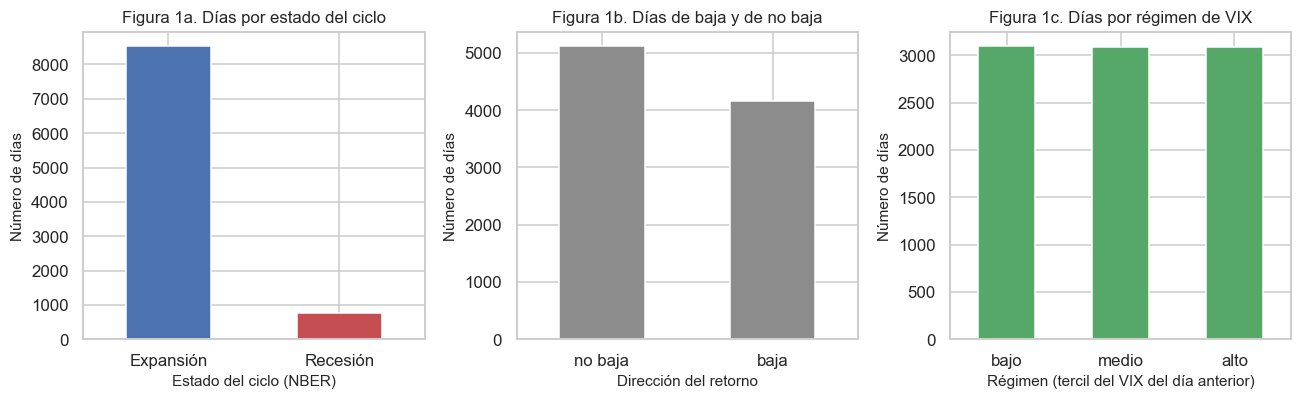

In [39]:
# 3.5.3 Código
print('▼ 3.5.4 Resultado')
def frec(s, nombre):
    t = s.value_counts(dropna=False).rename("frecuencia").to_frame(); t["%"] = (100 * t["frecuencia"] / t["frecuencia"].sum()).round(2)
    t.index.name = nombre; return t
f_est = frec(work["rec"].map(NOMBRE), "estado del ciclo (días)"); f_baja = frec(work["dia_baja"].map({0: "no baja", 1: "baja"}), "día de baja")
f_reg = frec(work["regimen_vix"].astype(object).fillna("sin dato"), "régimen de VIX")
for t in (f_est, f_baja, f_reg): display(t)
cruz = pd.crosstab(work["regimen_vix"], work["rec"].map(NOMBRE), normalize="index").mul(100).round(1)
print("Porcentaje de días en cada estado del ciclo, por régimen de VIX:"); display(cruz)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.8))
f_est["frecuencia"].reindex(["Expansión", "Recesión"]).plot.bar(ax=ax[0], color=[COL[0], COL[1]], rot=0)
ax[0].set(title="Figura 1a. Días por estado del ciclo", xlabel="Estado del ciclo (NBER)", ylabel="Número de días")
f_baja["frecuencia"].reindex(["no baja", "baja"]).plot.bar(ax=ax[1], color="#8C8C8C", rot=0)
ax[1].set(title="Figura 1b. Días de baja y de no baja", xlabel="Dirección del retorno", ylabel="Número de días")
f_reg["frecuencia"].reindex(["bajo", "medio", "alto"]).plot.bar(ax=ax[2], color="#55A868", rot=0)
ax[2].set(title="Figura 1c. Días por régimen de VIX", xlabel="Régimen (tercil del VIX del día anterior)", ylabel="Número de días")
guardar("fig01_frecuencias.png")
RES.update(pct_baja=float(100 * work["dia_baja"].mean()))

**3.5.5 Interpretación.** El 91.9 % de los días son de expansión y el 8.1 % de recesión: la comparación entre grupos es muy desbalanceada, lo que obliga a usar pruebas robustas a ese desbalance. El 44.9 % de los días fueron de baja. Los regímenes de VIX son iguales por construcción (un tercio cada uno). El cruce muestra que el VIX alto y la recesión van juntos: el 21.5 % de los días de VIX alto cae en recesión, frente al 2.8 % del régimen medio y el 0.1 % del bajo. Esto es relevante: usar el VIX y la recesión como "explicaciones" del riesgo implica que se solapan parcialmente.

### 3.6 Análisis exploratorio: variables cuantitativas

**3.6.1 Descripción.** Se calculan medidas de tendencia central, dispersión y forma para el retorno, su magnitud y el VIX, en conjunto y por estado del ciclo. El coeficiente de variación solo es interpretable para variables con media lejos de cero (el VIX); para el retorno, cuya media es casi cero, no se interpreta.

**3.6.2 Calcular el resumen descriptivo, en conjunto y por estado del ciclo**

In [40]:
# 3.6.3 Código
print('▼ 3.6.4 Resultado')
def resumen(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75])
    return pd.Series({"n": len(s), "media": s.mean(), "mediana": s.median(), "moda (redond. 0.1)": s.round(1).mode().iloc[0], "mín": s.min(), "máx": s.max(), "rango": s.max() - s.min(),
                      "varianza": s.var(ddof=1), "desv. est.": s.std(ddof=1), "Q1": q1, "Q3": q3, "IQR": q3 - q1, "asimetría": stats.skew(s), "curtosis exceso": stats.kurtosis(s)})
tab = pd.concat({"ret (%)": resumen(work["ret"]), "abs_ret (%)": resumen(work["abs_ret"]), "VIX": resumen(work["vix"])}, axis=1)
display(tab.round(3)); tab.to_csv(os.path.join(RES_DIR, "descriptivos_generales.csv"))
print("Coeficiente de variación del VIX:", round(work["vix"].std() / work["vix"].mean(), 3), "| del retorno: no interpretable (media ~ 0)")
por = pd.concat({NOMBRE[k]: pd.concat({"ret (%)": resumen(g["ret"]), "abs_ret (%)": resumen(g["abs_ret"]), "VIX": resumen(g["vix"])}, axis=1) for k, g in work.groupby("rec")}, axis=1)
display(por.round(3)); por.to_csv(os.path.join(RES_DIR, "descriptivos_por_estado.csv"))
RES.update(ret_media=float(work["ret"].mean()), ret_sd=float(work["ret"].std()), ret_asim=float(stats.skew(work["ret"])), ret_curt=float(stats.kurtosis(work["ret"])))

▼ 3.6.4 Resultado


,ret (%),abs_ret (%),VIX
n,9276.000,9276.000,9272.000
media,0.043,1.001,19.425
mediana,0.114,0.688,17.570
moda (redond. 0.1),0.100,0.100,13.400
mín,-13.149,0.000,9.140
máx,13.255,13.255,82.690
rango,26.404,13.255,73.550
varianza,2.130,1.130,59.551
desv. est.,1.460,1.063,7.717
Q1,-0.587,0.297,14.008


Coeficiente de variación del VIX: 0.397 | del retorno: no interpretable (media ~ 0)


Expansión                       Recesión                     
                     ret (%) abs_ret (%)       VIX  ret (%) abs_ret (%)      VIX
n                   8523.000    8523.000  8520.000  753.000     753.000  752.000
media                  0.049       0.937    18.348   -0.025       1.725   31.619
mediana                0.118       0.661    16.930    0.003       1.212   27.560
moda (redond. 0.1)     0.100       0.100    13.400   -0.100       0.100   22.900
mín                  -10.168       0.000     9.140  -13.149       0.001   14.900
máx                   13.255      13.255    52.330   11.159      13.149   82.690
rango                 23.423      13.255    43.190   24.309      13.148   67.790
varianza               1.792       0.916    36.039    5.963       2.986  164.294
desv. est.             1.339       0.957     6.003    2.442       1.728   12.818
Q1                    -0.554       0.287    13.720   -1.218       0.489   22.680
Q3                     0.739       1.264    21.560    1.207       2.411   36.205
IQR                    1.293       0.977     7.840    2.425       1.922   13.525
asimetría             -0.153       2.643     1.188   -0.122       2.090    1.520
curtosis exceso        5.775      13.485     1.601    3.201       6.431    1.997

**3.6.5 Interpretación.** El retorno diario medio es 0.043 %, menor que la mediana (0.114 %), con asimetría negativa (−0.18): las caídas grandes son algo más extremas que las alzas grandes. La desviación estándar es 1.46 % y la curtosis en exceso es 6.65, muy por encima de 0 (el valor de una normal): colas pesadas. El coeficiente de variación del retorno no se interpreta porque su media es casi cero; el del VIX (0.40) sí. Por estado del ciclo, la desviación estándar del retorno sube de 1.34 % (expansión) a 2.44 % (recesión), el rango intercuartílico de 1.29 a 2.43 y el VIX medio de 18.3 a 31.6. La media del retorno no difiere de forma visible (0.049 % frente a −0.025 %): lo que cambia es la dispersión, no la dirección promedio.

### 3.7 Análisis exploratorio: forma de la distribución del retorno

**3.7.1 Descripción.** Se compara la distribución empírica del retorno con una normal de igual media y desviación, mediante histograma y gráfico cuantil-cuantil (QQ), y se contrasta la normalidad con Jarque-Bera. La normalidad se contrasta, no se supone.

**3.7.2 Graficar histograma y QQ del retorno y aplicar Jarque-Bera**

▼ 3.7.4 Resultado


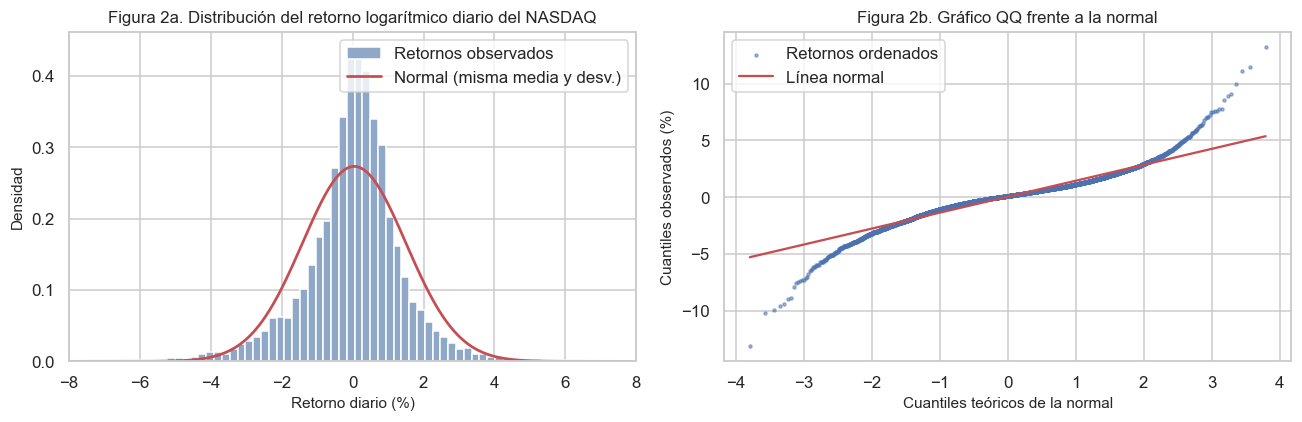

Jarque-Bera = 17,136, p < 0.001 | asimetría = -0.177 | curtosis en exceso = 6.65
Frecuencia de retornos < -3 desv. est.: observada 0.81 % | esperada bajo normalidad 0.13 %


In [41]:
# 3.7.3 Código
print('▼ 3.7.4 Resultado')
r_ = work["ret"].values; mu_, sd_ = r_.mean(), r_.std(ddof=1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(r_, bins=120, density=True, color="#8FA8C8", edgecolor="white", label="Retornos observados")
xs = np.linspace(-8, 8, 400); ax[0].plot(xs, stats.norm.pdf(xs, mu_, sd_), color="#C44E52", lw=1.8, label="Normal (misma media y desv.)")
ax[0].set(xlim=(-8, 8), title="Figura 2a. Distribución del retorno logarítmico diario del NASDAQ", xlabel="Retorno diario (%)", ylabel="Densidad"); ax[0].legend()
(osm, osr), (sl, ic, _) = stats.probplot(r_, dist="norm")
ax[1].scatter(osm, osr, s=4, alpha=.5, color="#4C72B0", label="Retornos ordenados"); ax[1].plot(osm, ic + sl * osm, color="#C44E52", label="Línea normal")
ax[1].set(title="Figura 2b. Gráfico QQ frente a la normal", xlabel="Cuantiles teóricos de la normal", ylabel="Cuantiles observados (%)"); ax[1].legend()
guardar("fig02_distribucion_retornos.png")
jb, pjb = stats.jarque_bera(r_)
print(f"Jarque-Bera = {jb:,.0f}, p {p_fmt(pjb)} | asimetría = {stats.skew(r_):.3f} | curtosis en exceso = {stats.kurtosis(r_):.2f}")
print("Frecuencia de retornos < -3 desv. est.: observada", f"{100 * np.mean(r_ < mu_ - 3 * sd_):.2f} %", "| esperada bajo normalidad", f"{100 * stats.norm.cdf(-3):.2f} %")
RES.update(jb=float(jb), jb_p=float(pjb))

**3.7.5 Interpretación.** El histograma es más puntiagudo en el centro y tiene colas más gruesas que la normal, y en el gráfico QQ los puntos se separan de la recta en ambos extremos. Jarque-Bera (17,136, p < 0.001) rechaza la normalidad. Un movimiento de más de 3 desviaciones estándar a la baja ocurre en el 0.81 % de los días, unas 6 veces la frecuencia que daría una normal (0.13 %). Consecuencia: un VaR calculado como si los retornos fueran normales subestimará las pérdidas extremas.

### 3.8 Análisis exploratorio: evolución en el tiempo y ciclo económico

**3.8.1 Descripción.** Se grafican el logaritmo del índice y el VIX a lo largo de 1990-2026, sombreando los meses de recesión del NBER, para ver el comportamiento conjunto y el contexto de los episodios.

**3.8.2 Graficar el índice (escala logarítmica) y el VIX con las recesiones sombreadas**

▼ 3.8.4 Resultado


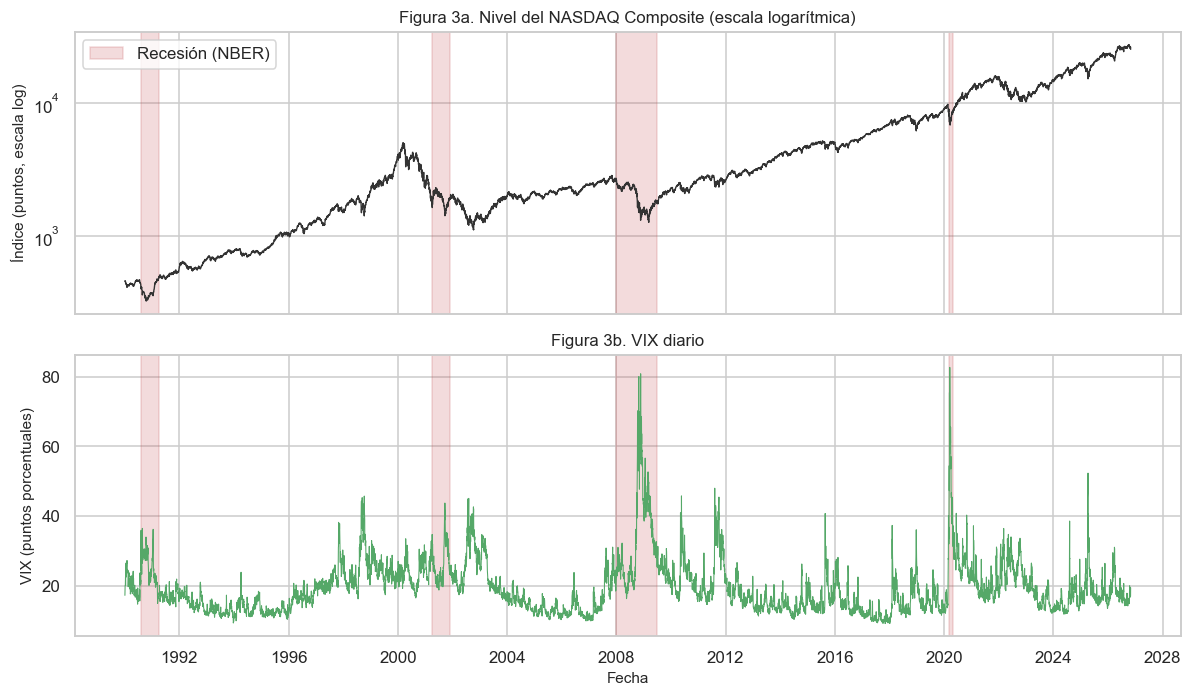

Máximo del VIX: 82.69 el 2020-03-16 | mínimo del NASDAQ en la muestra: 325.44 el 1990-10-16


In [42]:
# 3.8.3 Código
print('▼ 3.8.4 Resultado')
us = trab["USREC"].set_index("fecha")["valor"]
bloques = (us.diff().fillna(us.iloc[0]) != 0).cumsum(); spans = [(g.index.min(), g.index.max() + pd.offsets.MonthEnd(0)) for _, g in us[us == 1].groupby(bloques[us == 1])]
fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
ax[0].plot(dias.index, dias["nasdaq"], color="#333333", lw=.9); ax[0].set_yscale("log")
ax[0].set(title="Figura 3a. Nivel del NASDAQ Composite (escala logarítmica)", ylabel="Índice (puntos, escala log)")
ax[1].plot(dias.index, dias["vix"], color="#55A868", lw=.7); ax[1].set(title="Figura 3b. VIX diario", xlabel="Fecha", ylabel="VIX (puntos porcentuales)")
for a in ax:
    for i, (s, e) in enumerate(spans): a.axvspan(s, e, color=COL[1], alpha=.2, label="Recesión (NBER)" if i == 0 else None)
ax[0].legend(loc="upper left"); guardar("fig03_serie_ciclo.png")
print("Máximo del VIX:", dias["vix"].max(), "el", dias["vix"].idxmax().date(), "| mínimo del NASDAQ en la muestra:", dias["nasdaq"].min(), "el", dias["nasdaq"].idxmin().date())

**3.8.5 Interpretación.** Las cuatro recesiones coinciden con caídas del índice y con aumentos del VIX, pero la relación no es exacta: la caída de 2000-2002 empezó antes de que el NBER fechara la recesión de 2001, y hay picos de VIX fuera de recesión (1998, 2002-2003, 2011, abril de 2025). El VIX máximo (82.69) ocurre el 16-mar-2020. Esto recuerda que el fechado del NBER es una definición macroeconómica y no una marca de los episodios de estrés bursátil.

### 3.9 Análisis exploratorio: comparación descriptiva por grupos

**3.9.1 Descripción.** Se compara descriptivamente la magnitud del retorno entre estados del ciclo y entre regímenes de VIX, con diagramas de caja y con medidas de cola: percentiles de pérdida y frecuencia de movimientos grandes.

**3.9.2 Comparar la dispersión y las colas por estado del ciclo y por régimen de VIX**

▼ 3.9.4 Resultado


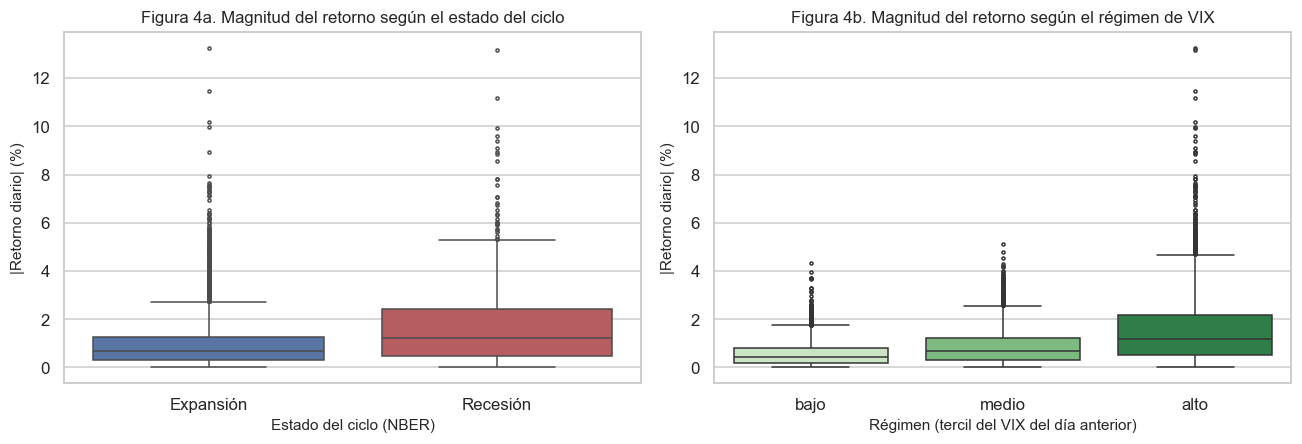

,días,desv. est. (%),percentil 1 (%),percentil 5 (%),mínimo (%),% días con |ret| > 3,% días con |ret| > 5
rec,,,,,,,
Expansión,8523,1.339,-3.878,-2.218,-10.168,3.848,0.634
Recesión,753,2.442,-6.552,-3.861,-13.149,17.663,5.046


,size,mean,median,std
regimen_vix,,,,
bajo,3094,0.585,0.452,0.517
medio,3089,0.864,0.679,0.736
alto,3089,1.555,1.178,1.444


In [43]:
# 3.9.3 Código
print('▼ 3.9.4 Resultado')
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
sns.boxplot(data=work, x=work["rec"].map(NOMBRE), y="abs_ret", order=["Expansión", "Recesión"], palette=[COL[0], COL[1]], fliersize=2, ax=ax[0])
ax[0].set(title="Figura 4a. Magnitud del retorno según el estado del ciclo", xlabel="Estado del ciclo (NBER)", ylabel="|Retorno diario| (%)")
sns.boxplot(data=work.dropna(subset=["regimen_vix"]), x="regimen_vix", y="abs_ret", order=["bajo", "medio", "alto"], palette="Greens", fliersize=2, ax=ax[1])
ax[1].set(title="Figura 4b. Magnitud del retorno según el régimen de VIX", xlabel="Régimen (tercil del VIX del día anterior)", ylabel="|Retorno diario| (%)")
guardar("fig04_cajas_abs_ret.png")
g = work.groupby(work["rec"].map(NOMBRE))["ret"]
comp = pd.DataFrame({"días": g.size(), "desv. est. (%)": g.std(), "percentil 1 (%)": g.quantile(.01), "percentil 5 (%)": g.quantile(.05), "mínimo (%)": g.min(),
                     "% días con |ret| > 3": g.apply(lambda s: 100 * (s.abs() > 3).mean()), "% días con |ret| > 5": g.apply(lambda s: 100 * (s.abs() > 5).mean())})
display(comp.round(3)); comp.to_csv(os.path.join(RES_DIR, "comparacion_descriptiva_estado.csv"))
rg = work.dropna(subset=["regimen_vix"]).groupby("regimen_vix", observed=True)["abs_ret"].agg(["size", "mean", "median", "std"]); display(rg.round(3))
RES.update(sd_exp=float(g.std()["Expansión"]), sd_rec=float(g.std()["Recesión"]), p1_exp=float(g.quantile(.01)["Expansión"]), p1_rec=float(g.quantile(.01)["Recesión"]))

**3.9.5 Interpretación.** Las cajas de |retorno| están desplazadas hacia arriba en recesión y en el régimen de VIX alto, y su dispersión es mayor. En recesión el percentil 1 del retorno es −6.55 % (en expansión, −3.88 %); el 17.7 % de los días tiene movimientos de más de 3 % (3.8 % en expansión) y el 5.0 % de más de 5 % (0.6 % en expansión). Por régimen de VIX, la magnitud media del retorno es 0.59 % (bajo), 0.86 % (medio) y 1.56 % (alto): casi 2.7 veces entre los extremos. Son diferencias descriptivas; la inferencia viene en la sección 4.

### 3.10 Supuestos de la serie de retornos: estacionariedad, autocorrelación y efectos ARCH

**3.10.1 Descripción.** Se evalúan propiedades de la serie que condicionan las pruebas posteriores: estacionariedad (ADF y KPSS, que tienen hipótesis nulas opuestas), autocorrelación (Ljung-Box sobre el retorno, su cuadrado y su valor absoluto) y efectos ARCH (agrupamiento de la volatilidad).

**3.10.2 Aplicar ADF, KPSS, Ljung-Box y ARCH-LM, y graficar la autocorrelación**

▼ 3.10.4 Resultado


,serie,ADF (t),rezagos,ADF: lectura,KPSS,KPSS: lectura
0,log del índice (nivel),-0.41,16,no rechaza raíz unitaria,57.804,rechaza estacionariedad (5 %)
1,retorno diario,-22.86,15,rechaza raíz unitaria (5 %),0.089,no rechaza estacionariedad


,serie,Ljung-Box Q (10 rezagos),valor p
0,retorno,44.0,< 0.001
1,retorno al cuadrado,6014.6,< 0.001
2,|retorno|,8561.9,< 0.001


ARCH-LM (5 rezagos) sobre el retorno: LM = 1694.1, p < 0.001


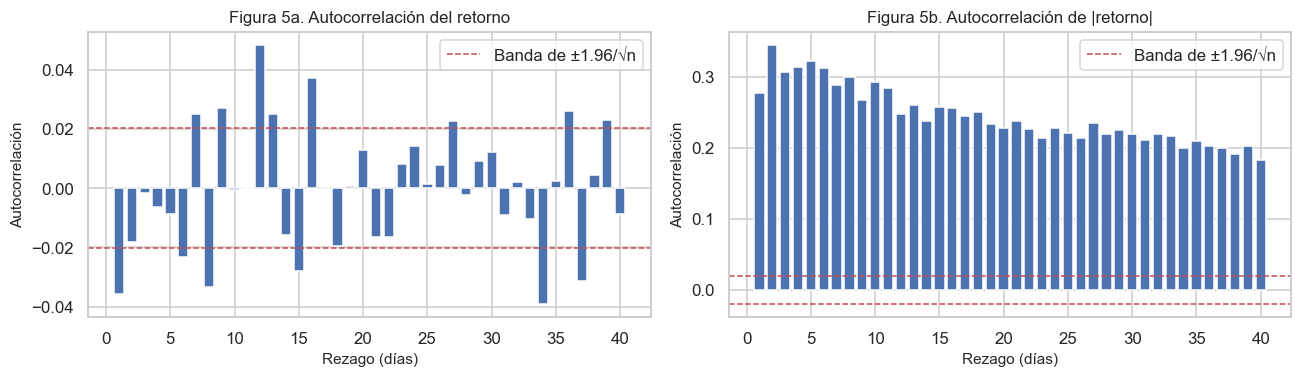

In [44]:
# 3.10.3 Código
print('▼ 3.10.4 Resultado')
lp = np.log(dias["nasdaq"].dropna().values)
res = []
for nom, x in [("log del índice (nivel)", lp), ("retorno diario", work["ret"].values)]:
    a, p_ = adf_test(x); k_, l_ = kpss_test(x)
    res.append([nom, round(a, 2), p_, "no rechaza raíz unitaria" if a > -2.86 else "rechaza raíz unitaria (5 %)", round(k_, 3), "rechaza estacionariedad (5 %)" if k_ > .463 else "no rechaza estacionariedad"])
display(pd.DataFrame(res, columns=["serie", "ADF (t)", "rezagos", "ADF: lectura", "KPSS", "KPSS: lectura"]))
rows = []
for nom, x in [("retorno", work["ret"].values), ("retorno al cuadrado", work["ret"].values ** 2), ("|retorno|", work["abs_ret"].values)]:
    q, p_ = ljung_box(x, 10); rows.append([nom, round(q, 1), p_fmt(p_)])
display(pd.DataFrame(rows, columns=["serie", "Ljung-Box Q (10 rezagos)", "valor p"]))
lm, plm = arch_lm(work["ret"].values - work["ret"].mean(), 5); print(f"ARCH-LM (5 rezagos) sobre el retorno: LM = {lm:.1f}, p {p_fmt(plm)}")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6)); lags = np.arange(1, 41); cb = 1.96 / np.sqrt(len(work))
for a_, x, ttl in [(ax[0], work["ret"].values, "Figura 5a. Autocorrelación del retorno"), (ax[1], work["abs_ret"].values, "Figura 5b. Autocorrelación de |retorno|")]:
    a_.bar(lags, acf(x, 40), color="#4C72B0"); a_.axhline(cb, color="#C44E52", ls="--", lw=1, label="Banda de ±1.96/√n"); a_.axhline(-cb, color="#C44E52", ls="--", lw=1)
    a_.set(title=ttl, xlabel="Rezago (días)", ylabel="Autocorrelación"); a_.legend()
guardar("fig05_autocorrelacion.png")
RES.update(lb_ret_p=float(ljung_box(work["ret"].values, 10)[1]), lb_abs_p=float(ljung_box(work["abs_ret"].values, 10)[1]), archlm_p=float(plm))

**3.10.5 Interpretación.** El nivel del índice no es estacionario (ADF −0.41 no rechaza raíz unitaria; KPSS 57.8 rechaza estacionariedad), mientras que el retorno sí lo es (ADF −22.9; KPSS 0.089), por lo que se trabaja con retornos. La autocorrelación del retorno es pequeña pero detectable (Ljung-Box Q = 44.0), pero la de su cuadrado (Q = 6,014.6) y la de su valor absoluto (Q = 8,561.9) son enormes, y el ARCH-LM (1,694.1) lo confirma: la volatilidad se agrupa en rachas. Esto significa que los días no son independientes en su varianza, por lo que las pruebas de comparación de grupos usan el mes como unidad y errores robustos, y justifica el uso de un modelo GARCH.

## 4. Modelado

### 4.1 Análisis bivariado A: magnitud del retorno y VIX del día anterior (Spearman)

**4.1.1 Descripción.** **Pregunta:** ¿se asocia el VIX del día anterior con la magnitud del retorno del día? **H0:** rho de Spearman = 0; **H1:** rho ≠ 0. Se usa Spearman porque la relación esperada es monótona pero no lineal y ambas variables son asimétricas y con colas pesadas. Nivel de significación 0.05. Las observaciones diarias no son independientes (la volatilidad se agrupa), por lo que el valor p es orientativo y el coeficiente es la medida principal.

**4.1.2 Calcular Spearman entre |retorno| y VIX rezagado y graficar la relación**

▼ 4.1.4 Resultado
Spearman |ret_t| vs VIX_(t-1): rho = 0.385, p < 0.001, n = 9272
   dentro de Expansión: rho = 0.369, p < 0.001, n = 8520
   dentro de Recesión: rho = 0.305, p < 0.001, n = 752


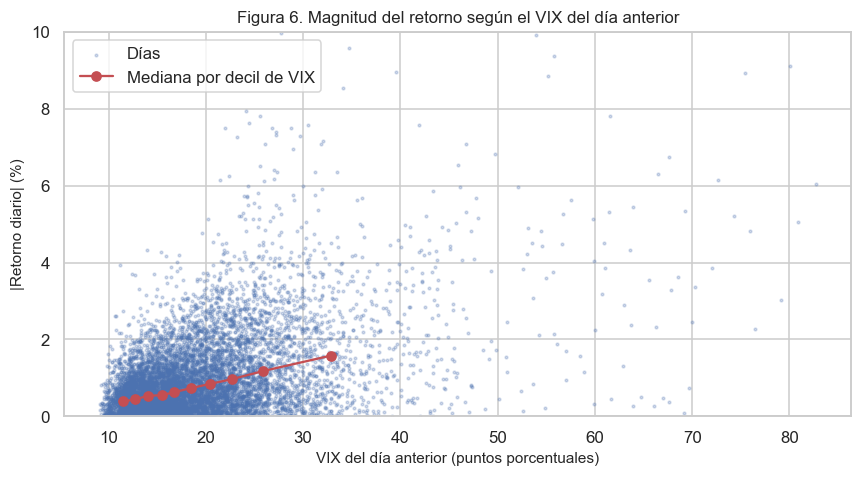

In [45]:
# 4.1.3 Código
print('▼ 4.1.4 Resultado')
d = work.dropna(subset=["vix_lag"])
rho, p = stats.spearmanr(d["vix_lag"], d["abs_ret"])
print(f"Spearman |ret_t| vs VIX_(t-1): rho = {rho:.3f}, p {p_fmt(p)}, n = {len(d)}")
for k, g in d.groupby("rec"):
    r_k, p_k = stats.spearmanr(g["vix_lag"], g["abs_ret"]); print(f"   dentro de {NOMBRE[k]}: rho = {r_k:.3f}, p {p_fmt(p_k)}, n = {len(g)}")
d = d.assign(dec=pd.qcut(d["vix_lag"], 10)); med = d.groupby("dec", observed=True).agg(x=("vix_lag", "median"), y=("abs_ret", "median"))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(d["vix_lag"], d["abs_ret"], s=3, alpha=.25, color="#4C72B0", label="Días")
ax.plot(med["x"], med["y"], "o-", color="#C44E52", label="Mediana por decil de VIX")
ax.set(title="Figura 6. Magnitud del retorno según el VIX del día anterior", xlabel="VIX del día anterior (puntos porcentuales)", ylabel="|Retorno diario| (%)", ylim=(0, 10)); ax.legend()
guardar("fig06_spearman_vix_abs.png")
RES["spearman"] = dict(rho=float(rho), p=float(p), n=int(len(d)))

**4.1.5 Interpretación.** Rho de Spearman = 0.385 (p < 0.001, n = 9,272): a mayor VIX del día anterior, mayor magnitud del retorno del día. La asociación es de intensidad moderada y se mantiene dentro de cada estado del ciclo (0.369 en expansión y 0.305 en recesión), así que no es solo un efecto de la recesión. El gráfico muestra la mediana de |retorno| subiendo con cada decil de VIX. El valor p debe leerse con cautela (los días no son independientes) y la asociación no implica causalidad: el VIX es en sí una medida de volatilidad esperada del mercado.

### 4.2 Análisis bivariado B: régimen de VIX y días de baja (chi-cuadrado)

**4.2.1 Descripción.** **Pregunta:** ¿está asociado el régimen de VIX del día anterior (bajo, medio, alto) con que el día sea de baja? **H0:** independencia; **H1:** asociación. Se usa chi-cuadrado de independencia sobre una tabla de 3 x 2 y se revisan las frecuencias esperadas (todas deben ser al menos 5). Se mide la intensidad con la V de Cramér.

**4.2.2 Construir la tabla de contingencia, aplicar chi-cuadrado y calcular V de Cramér**

▼ 4.2.4 Resultado


dia_baja,baja,no baja
regimen_vix,,
bajo,1358,1736
medio,1402,1687
alto,1404,1685


Frecuencia esperada mínima: 1387.3 (condición: >= 5)
Chi-cuadrado = 1.95, gl = 2, p 0.378 | V de Cramér = 0.014


regimen_vix
bajo     43.89
medio    45.39
alto     45.45
Name: % de días de baja, dtype: float64

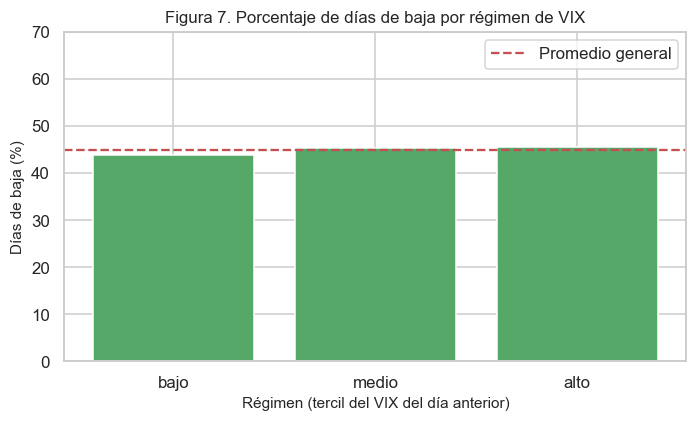

In [46]:
# 4.2.3 Código
print('▼ 4.2.4 Resultado')
d = work.dropna(subset=["regimen_vix"])
tabla = pd.crosstab(d["regimen_vix"], d["dia_baja"].map({0: "no baja", 1: "baja"}))
chi2, p, dof, esp = stats.chi2_contingency(tabla)
V = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))
display(tabla); print("Frecuencia esperada mínima:", round(esp.min(), 1), "(condición: >= 5)")
print(f"Chi-cuadrado = {chi2:.2f}, gl = {dof}, p {p_fmt(p)} | V de Cramér = {V:.3f}")
pct = (100 * tabla["baja"] / tabla.sum(axis=1)); display(pct.round(2).rename("% de días de baja"))
fig, ax = plt.subplots(figsize=(6.5, 4)); ax.bar(pct.index.astype(str), pct.values, color="#55A868"); ax.axhline(100 * d["dia_baja"].mean(), color="#C44E52", ls="--", label="Promedio general")
ax.set(title="Figura 7. Porcentaje de días de baja por régimen de VIX", xlabel="Régimen (tercil del VIX del día anterior)", ylabel="Días de baja (%)", ylim=(0, 70)); ax.legend()
guardar("fig07_baja_por_regimen.png")
RES["chi2"] = dict(chi2=float(chi2), p=float(p), V=float(V), esp_min=float(esp.min()))

**4.2.5 Interpretación.** Chi-cuadrado = 1.95 (2 gl, p = 0.378) con V de Cramér = 0.014: no se rechaza la independencia. Los porcentajes de días de baja son casi iguales: 43.9 % (VIX bajo), 45.4 % (medio) y 45.5 % (alto). Se cumple la condición de frecuencias esperadas (mínima 1,387). Con más de 9,000 observaciones, la ausencia de diferencia es informativa: el nivel del VIX se asocia con cuánto se mueve el mercado (4.1) pero no con en qué dirección. No rechazar H0 no prueba que no exista ninguna asociación, pero si existe es de tamaño despreciable.

### 4.3 Análisis bivariado C: retorno y cambio del VIX (regresión lineal con errores robustos)

**4.3.1 Descripción.** **Pregunta:** ¿cuánto se mueve el retorno del día cuando el VIX cambia ese mismo día? **Modelo:** ret = b0 + b1 x dVIX + error. **H0:** b1 = 0; **H1:** b1 ≠ 0. Se estima por mínimos cuadrados con errores estándar de Newey-West (robustos a heterocedasticidad y autocorrelación) y se diagnostican los residuos: autocorrelación, efectos ARCH, heterocedasticidad (Breusch-Pagan), normalidad y observaciones influyentes (distancia de Cook). La asociación es contemporánea; no implica causalidad.

**4.3.2 Estimar la regresión, calcular errores robustos y diagnosticar los supuestos**

▼ 4.3.4 Resultado


,coef.,EE clásico,EE Newey-West,t (NW),valor p
constante,0.0432,0.0108,0.0108,3.9878,0.0001
dVIX,-0.6149,0.0065,0.0200,-30.6890,0.0000


R2 = 0.491 | n = 9268 | rezagos Newey-West = 10
Diagnóstico de residuos: Ljung-Box p 0.002 | ARCH-LM p < 0.001 | Breusch-Pagan p 0.004 | Jarque-Bera p < 0.001
Distancia de Cook: máximo = 0.529 (regla de alerta: > 1) | observaciones con D > 4/n: 498


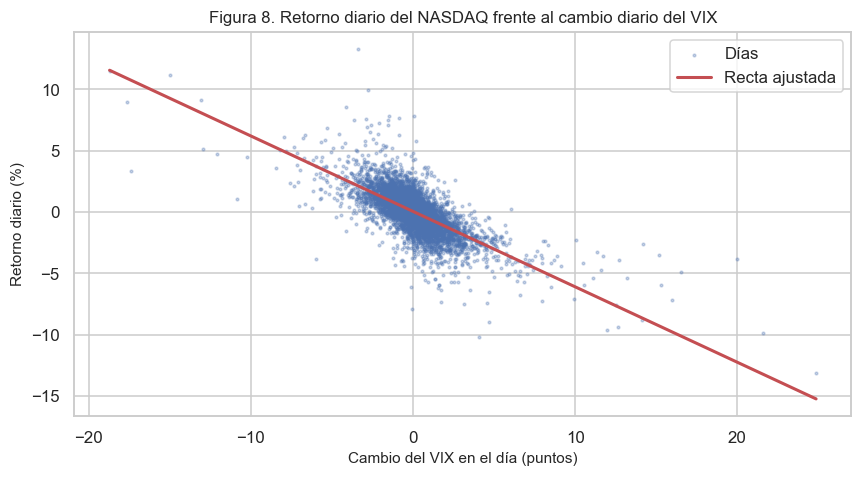

In [47]:
# 4.3.3 Código
print('▼ 4.3.4 Resultado')
d = work.dropna(subset=["dvix"]); y = d["ret"].values; X = np.column_stack([np.ones(len(d)), d["dvix"].values])
m = ols_full(X, y); b, seh, sec = m["b"], m["se_h"], m["se_c"]; tstat = b / seh; pval = 2 * stats.t.sf(np.abs(tstat), m["n"] - m["k"])
tabr = pd.DataFrame({"coef.": b, "EE clásico": sec, "EE Newey-West": seh, "t (NW)": tstat, "valor p": pval}, index=["constante", "dVIX"])
display(tabr.round(4)); print(f"R2 = {m['r2']:.3f} | n = {m['n']} | rezagos Newey-West = {m['L']}")
e = m["e"]; q, pq = ljung_box(e, 10); lm, plm = arch_lm(e, 5); bp, pbp = breusch_pagan(X, e); jbe, pjb = stats.jarque_bera(e)
XtXi = np.linalg.inv(X.T @ X); h = np.einsum("ij,jk,ik->i", X, XtXi, X); s2 = e @ e / (m["n"] - 2); cook = e ** 2 / (2 * s2) * h / (1 - h) ** 2
print(f"Diagnóstico de residuos: Ljung-Box p {p_fmt(pq)} | ARCH-LM p {p_fmt(plm)} | Breusch-Pagan p {p_fmt(pbp)} | Jarque-Bera p {p_fmt(pjb)}")
print(f"Distancia de Cook: máximo = {cook.max():.3f} (regla de alerta: > 1) | observaciones con D > 4/n: {int((cook > 4 / m['n']).sum())}")
fig, ax = plt.subplots(figsize=(8, 4.5)); ax.scatter(d["dvix"], d["ret"], s=3, alpha=.3, color="#4C72B0", label="Días")
xs = np.linspace(d["dvix"].min(), d["dvix"].max(), 100); ax.plot(xs, b[0] + b[1] * xs, color="#C44E52", lw=2, label="Recta ajustada")
ax.set(title="Figura 8. Retorno diario del NASDAQ frente al cambio diario del VIX", xlabel="Cambio del VIX en el día (puntos)", ylabel="Retorno diario (%)"); ax.legend()
guardar("fig08_regresion_dvix.png")
RES["ols"] = dict(b1=float(b[1]), se_hac=float(seh[1]), t=float(tstat[1]), p=float(pval[1]), r2=float(m["r2"]), n=int(m["n"]), lb_p=float(pq), archlm_p=float(plm), bp_p=float(pbp), cook_max=float(cook.max()))

**4.3.5 Interpretación.** Por cada punto que sube el VIX en el día, el retorno del NASDAQ del mismo día baja en promedio 0.61 puntos porcentuales (coeficiente −0.615, error Newey-West 0.020, t = −30.7, p < 0.001; R² = 0.49). Es una relación contemporánea e inversa muy fuerte. Los errores de Newey-West (0.020) son tres veces los clásicos (0.0065): sin la corrección el resultado parecería más preciso de lo que es. Los diagnósticos muestran autocorrelación débil (p = 0.002), efectos ARCH y heterocedasticidad (p < 0.001 y 0.004) y no normalidad de los residuos, lo que confirma que se necesitan errores robustos. La distancia de Cook máxima es 0.53 (por debajo de 1): ninguna observación domina el ajuste. Hay 498 días por encima de 4/n (5.4 %), que son días de crisis y se conservan. La relación no es causal: el retorno y el VIX se mueven a la vez ante la misma información.

### 4.4 Inferencia paramétrica: log-volatilidad mensual en recesión y expansión (t de Welch)

**4.4.1 Descripción.** **Pregunta:** ¿difiere el nivel de volatilidad entre meses de recesión y de expansión? **Variable:** log-volatilidad mensual = logaritmo de la desviación estándar de los retornos diarios del mes (meses con al menos 10 días). Se usa el mes como unidad porque los días no son independientes en varianza. **H0:** igual media en ambos estados; **H1:** medias distintas (bilateral); α = 0.05. **Prueba:** t de Welch para muestras independientes (no supone varianzas iguales). **Supuestos revisados:** normalidad en cada grupo (QQ y Shapiro-Wilk), varianzas (Levene), independencia (autocorrelación de la serie mensual) y valores extremos. Se añade una regresión sobre la variable recesión con errores de Newey-West como control de la dependencia temporal. Se reporta el intervalo de confianza de la diferencia y el tamaño del efecto (d de Cohen).

**4.4.2 Construir la serie mensual, revisar supuestos y aplicar t de Welch con IC y d de Cohen**

▼ 4.4.4 Resultado
Meses analizados: 442 (recesión: 36, expansión: 406)
Shapiro-Wilk (normalidad), valor p: {'Expansión': '< 0.001', 'Recesión': '0.940'} | Levene (varianzas iguales), valor p: 0.764
Autocorrelación de la log-volatilidad mensual: rezago 1 = 0.70, Ljung-Box(12) p < 0.001


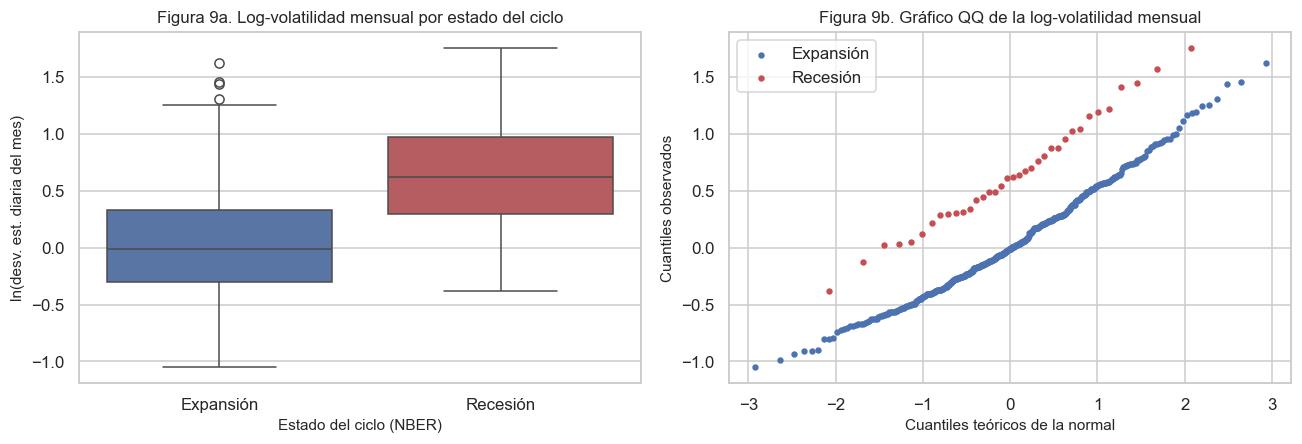


Media de log-volatilidad: recesión 0.645 | expansión 0.040 | diferencia 0.604  IC 95 % [0.430, 0.779]
t de Welch = 6.99, gl = 40.9, p < 0.001 | d de Cohen = 1.27
Control con Newey-West (12 rezagos): coef. recesión = 0.604, EE = 0.147, p < 0.001
Interpretación en escala original: la volatilidad mensual típica en recesión es 1.83 veces la de expansión (razón de medias geométricas).


In [48]:
# 4.4.3 Código
print('▼ 4.4.4 Resultado')
def mensual(w):
    g = w.groupby(w.index.to_period("M"))
    m = pd.DataFrame({"n_dias": g.size(), "sd": g["ret"].std(ddof=1), "rec": g["rec"].first()})
    m = m[m["n_dias"] >= MIN_DIAS_MES].copy(); m["logvol"] = np.log(m["sd"]); return m

def c1(m):
    """Pruebas de C1 sobre la log-volatilidad mensual."""
    a, b = m.loc[m.rec == 1, "logvol"].values, m.loc[m.rec == 0, "logvol"].values
    t, p = stats.ttest_ind(a, b, equal_var=False)
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b); gl = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))
    dif = a.mean() - b.mean(); ee = np.sqrt(va + vb); ic = (dif - stats.t.ppf(.975, gl) * ee, dif + stats.t.ppf(.975, gl) * ee)
    U, pu = stats.mannwhitneyu(a, b, alternative="two-sided"); cles = U / (len(a) * len(b))
    X = np.column_stack([np.ones(len(m)), m["rec"].values]); r = ols_full(X, m["logvol"].values, L=12); th = r["b"][1] / r["se_h"][1]
    return dict(n_rec=len(a), n_exp=len(b), media_rec=a.mean(), media_exp=b.mean(), dif=dif, ic_lo=ic[0], ic_hi=ic[1], t=t, gl=gl, p_welch=p, d=cohen_d(a, b),
                U=U, p_mw=pu, cles=cles, rb=2 * cles - 1, b_hac=r["b"][1], se_hac=r["se_h"][1], p_hac=2 * stats.t.sf(abs(th), len(m) - 2))

mens = mensual(work); a_ = mens.loc[mens.rec == 1, "logvol"]; b_ = mens.loc[mens.rec == 0, "logvol"]
print(f"Meses analizados: {len(mens)} (recesión: {len(a_)}, expansión: {len(b_)})")
sh = {NOMBRE[k]: p_fmt(float(stats.shapiro(mens.loc[mens.rec == k, "logvol"])[1])) for k in (0, 1)}
print("Shapiro-Wilk (normalidad), valor p:", sh, "| Levene (varianzas iguales), valor p:", p_fmt(float(stats.levene(a_, b_, center="median")[1])))
q, pq = ljung_box(mens["logvol"].values, 12); print(f"Autocorrelación de la log-volatilidad mensual: rezago 1 = {acf(mens['logvol'].values, 1)[0]:.2f}, Ljung-Box(12) p {p_fmt(pq)}")
R = c1(mens); RES["c1"] = {k: float(v) for k, v in R.items()}
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
sns.boxplot(x=mens["rec"].map(NOMBRE), y=mens["logvol"], order=["Expansión", "Recesión"], palette=[COL[0], COL[1]], ax=ax[0])
ax[0].set(title="Figura 9a. Log-volatilidad mensual por estado del ciclo", xlabel="Estado del ciclo (NBER)", ylabel="ln(desv. est. diaria del mes)")
for k in (0, 1):
    (osm, osr), (sl, ic_, _) = stats.probplot(mens.loc[mens.rec == k, "logvol"], dist="norm"); ax[1].scatter(osm, osr, s=10, color=COL[k], label=NOMBRE[k])
ax[1].set(title="Figura 9b. Gráfico QQ de la log-volatilidad mensual", xlabel="Cuantiles teóricos de la normal", ylabel="Cuantiles observados"); ax[1].legend()
guardar("fig09_logvol_mensual.png")
print(f"\nMedia de log-volatilidad: recesión {R['media_rec']:.3f} | expansión {R['media_exp']:.3f} | diferencia {R['dif']:.3f}  IC 95 % [{R['ic_lo']:.3f}, {R['ic_hi']:.3f}]")
print(f"t de Welch = {R['t']:.2f}, gl = {R['gl']:.1f}, p {p_fmt(R['p_welch'])} | d de Cohen = {R['d']:.2f}")
print(f"Control con Newey-West (12 rezagos): coef. recesión = {R['b_hac']:.3f}, EE = {R['se_hac']:.3f}, p {p_fmt(R['p_hac'])}")
print(f"Interpretación en escala original: la volatilidad mensual típica en recesión es {np.exp(R['dif']):.2f} veces la de expansión (razón de medias geométricas).")

**4.4.5 Interpretación.** La log-volatilidad mensual media es 0.645 en recesión y 0.040 en expansión: una diferencia de 0.604 (IC 95 % [0.43, 0.78]), con t de Welch = 6.99, 40.9 gl y p < 0.001, y una d de Cohen de 1.27 (efecto grande, según la convención de que 0.8 ya es grande). En la escala original, la volatilidad mensual típica en recesión es 1.83 veces la de expansión. Se rechaza H0. **Supuestos:** en expansión la log-volatilidad se aparta de la normal (Shapiro p < 0.001), pero con 406 meses la prueba t es robusta; en recesión no hay evidencia de apartarse (p = 0.94); las varianzas son compatibles (Levene p = 0.76), y Welch no las exige iguales. La **independencia no se cumple**: la autocorrelación al primer rezago es 0.70. Por eso se añadió la regresión con errores de Newey-West: mismo coeficiente (0.604), pero error estándar de 0.147 (cerca de 1.7 veces el implícito en Welch, unos 0.086) y p < 0.001. La conclusión se mantiene, pero el IC de Welch es demasiado estrecho; el de la regresión es más realista. Además, los 36 meses de recesión provienen de solo cuatro episodios, por lo que la evidencia efectiva es menor que 36 observaciones independientes.

### 4.5 Inferencia no paramétrica: log-volatilidad mensual (U de Mann-Whitney)

**4.5.1 Descripción.** **Pregunta:** la misma de 4.4, sin suponer normalidad. **H0:** la probabilidad de que un mes de recesión tenga mayor volatilidad que uno de expansión es 0.5; **H1:** es distinta de 0.5; α = 0.05. **Justificación:** con pocos meses de recesión y distribuciones que pueden alejarse de la normal, una prueba basada en rangos es más robusta. **Condiciones:** observaciones independientes (que aquí se cumple solo de forma aproximada, ver 4.4) y variable al menos ordinal. La prueba no compara medianas en general: compara la tendencia de un grupo a tomar valores mayores (dominancia estocástica). **Tamaño del efecto:** probabilidad de superioridad (CLES) y correlación biserial de rangos.

**4.5.2 Aplicar Mann-Whitney y calcular el tamaño del efecto; graficar las distribuciones acumuladas**

▼ 4.5.4 Resultado
U = 11880, p < 0.001
Probabilidad de superioridad (CLES): P(vol. mes de recesión > vol. mes de expansión) = 0.813 | correlación biserial de rangos = 0.626


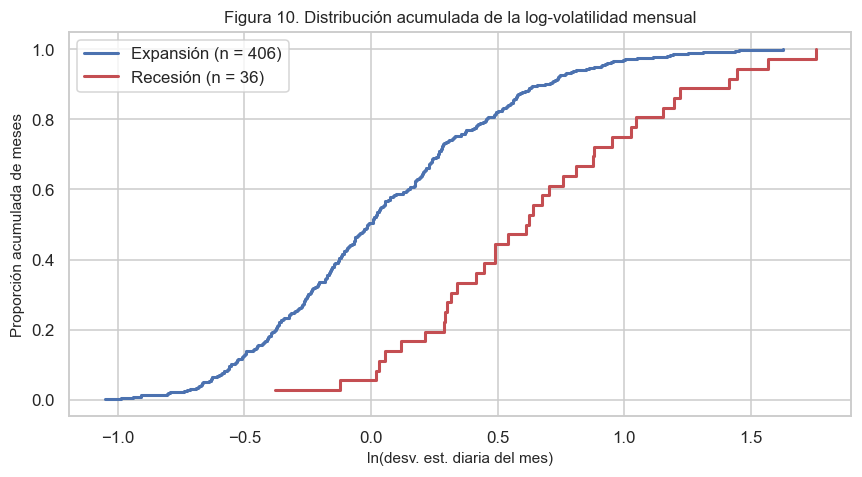

Forma de las distribuciones (condición para leer el resultado como desplazamiento): {'Expansión': {'IQR': 0.63, 'asimetria': 0.44}, 'Recesión': {'IQR': 0.67, 'asimetria': 0.27}}


In [49]:
# 4.5.3 Código
print('▼ 4.5.4 Resultado')
R = c1(mens)
print(f"U = {R['U']:.0f}, p {p_fmt(R['p_mw'])}")
print(f"Probabilidad de superioridad (CLES): P(vol. mes de recesión > vol. mes de expansión) = {R['cles']:.3f} | correlación biserial de rangos = {R['rb']:.3f}")
fig, ax = plt.subplots(figsize=(8, 4.5))
for k in (0, 1):
    x = np.sort(mens.loc[mens.rec == k, "logvol"]); ax.step(x, np.arange(1, len(x) + 1) / len(x), where="post", color=COL[k], lw=2, label=f"{NOMBRE[k]} (n = {len(x)})")
ax.set(title="Figura 10. Distribución acumulada de la log-volatilidad mensual", xlabel="ln(desv. est. diaria del mes)", ylabel="Proporción acumulada de meses"); ax.legend()
guardar("fig10_ecdf_logvol.png")
print("Forma de las distribuciones (condición para leer el resultado como desplazamiento):", {NOMBRE[k]: dict(IQR=round(float(np.subtract(*np.percentile(mens.loc[mens.rec == k, 'logvol'], [75, 25]))), 2), asimetria=round(float(stats.skew(mens.loc[mens.rec == k, 'logvol'])), 2)) for k in (0, 1)})

**4.5.5 Interpretación.** U = 11,880, p < 0.001: se rechaza H0. La probabilidad de superioridad es 0.813: si se toma al azar un mes de recesión y uno de expansión, en el 81 % de los pares el mes de recesión fue más volátil (correlación biserial de rangos 0.63). Como las formas de las dos distribuciones son parecidas (IQR 0.63 y 0.67; asimetría 0.44 y 0.27), el resultado puede leerse como un desplazamiento de la distribución de volatilidad hacia valores mayores en recesión, y no solo como un cambio de forma. La curva acumulada de recesión queda a la derecha de la de expansión en todo su recorrido. Mann-Whitney contrasta dominancia estocástica, no medianas. La conclusión coincide con la paramétrica, lo que da robustez a C1.

### 4.6 Magnitud de la diferencia: razón de volatilidades y análisis de sensibilidad (C2)

**4.6.1 Descripción.** Se estima la razón entre la desviación estándar diaria de los retornos en recesión y en expansión, con su intervalo de confianza por bootstrap estratificado de meses (se remuestrean meses completos dentro de cada estado, 5,000 réplicas). Luego se compara con la rejilla de umbrales fijada de antemano (1.10, 1.25, 1.50 y 2.00): un umbral se considera superado si el límite inferior del IC es mayor que él. El límite inferior del IC es el umbral de quiebre. Se añade la traducción a pérdidas: VaR histórico al 99 % en cada estado.

**4.6.2 Estimar la razón con IC por bootstrap y contrastarla con la rejilla de umbrales**

▼ 4.6.4 Resultado
Razón de volatilidades diarias (recesión / expansión) = 1.82, IC 95 % bootstrap [1.46, 2.18]


,umbral,estimación > umbral,límite inferior del IC > umbral
0,1.10,True,True
1,1.25,True,True
2,1.50,True,False
3,2.00,False,False


Umbral de quiebre continuo (límite inferior del IC): 1.46 | mayor umbral de la rejilla superado: 1.25
VaR histórico 99 % de un día (días de cada estado): expansión 3.88 %, recesión 6.55 % (cociente 1.69)


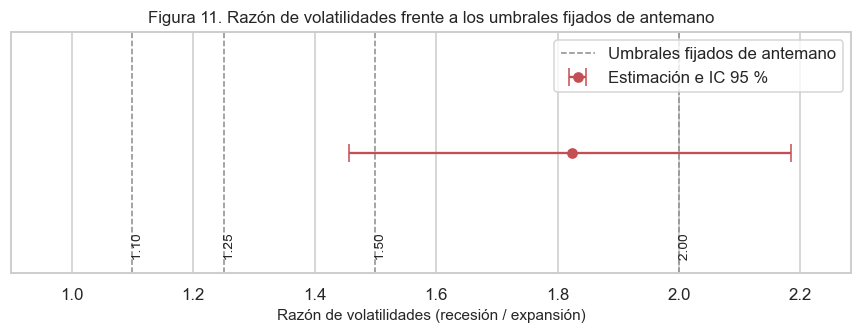

In [50]:
# 4.6.3 Código
print('▼ 4.6.4 Resultado')
def razon_boot(w, B=B_BOOT, rng=rng):
    tmp = pd.DataFrame({"rec": w["rec"].values, "mes": w.index.to_period("M"), "r": w["ret"].values}); tmp["r2"] = tmp["r"] ** 2
    ag = tmp.groupby(["rec", "mes"]).agg(n=("r", "size"), s=("r", "sum"), q=("r2", "sum")).reset_index(); sds = {}
    for k in (0, 1):
        z = ag[ag.rec == k]; n, s, q = z["n"].values, z["s"].values, z["q"].values; m_ = len(z)
        idx = rng.integers(0, m_, (B, m_)); N, S, Q = n[idx].sum(1), s[idx].sum(1), q[idx].sum(1); sds[k] = np.sqrt((Q - S ** 2 / N) / (N - 1))
    est = w.loc[w.rec == 1, "ret"].std(ddof=1) / w.loc[w.rec == 0, "ret"].std(ddof=1); rb = sds[1] / sds[0]
    return dict(razon=float(est), lo=float(np.percentile(rb, 2.5)), hi=float(np.percentile(rb, 97.5)))

RZ = razon_boot(work); RES["razon"] = RZ
print(f"Razón de volatilidades diarias (recesión / expansión) = {RZ['razon']:.2f}, IC 95 % bootstrap [{RZ['lo']:.2f}, {RZ['hi']:.2f}]")
sens = pd.DataFrame({"umbral": UMBRALES, "estimación > umbral": [RZ["razon"] > u for u in UMBRALES], "límite inferior del IC > umbral": [RZ["lo"] > u for u in UMBRALES]})
display(sens); superados = [u for u in UMBRALES if RZ["lo"] > u]
print("Umbral de quiebre continuo (límite inferior del IC):", round(RZ["lo"], 2), "| mayor umbral de la rejilla superado:", max(superados) if superados else "ninguno")
v99 = {k: -np.percentile(work.loc[work.rec == k, "ret"], 1) for k in (0, 1)}
print(f"VaR histórico 99 % de un día (días de cada estado): expansión {v99[0]:.2f} %, recesión {v99[1]:.2f} % (cociente {v99[1] / v99[0]:.2f})")
RES.update(var99_exp=float(v99[0]), var99_rec=float(v99[1]), umbral_max=(max(superados) if superados else None))
fig, ax = plt.subplots(figsize=(8, 3.2)); ax.errorbar(RZ["razon"], 0, xerr=[[RZ["razon"] - RZ["lo"]], [RZ["hi"] - RZ["razon"]]], fmt="o", color="#C44E52", capsize=6, label="Estimación e IC 95 %")
for i, u in enumerate(UMBRALES):
    ax.axvline(u, color="#8C8C8C", ls="--", lw=1, label="Umbrales fijados de antemano" if i == 0 else None)
    ax.text(u, 0.04, f" {u:.2f}", rotation=90, va="bottom", ha="left", fontsize=9, transform=ax.get_xaxis_transform())
ax.set(title="Figura 11. Razón de volatilidades frente a los umbrales fijados de antemano", xlabel="Razón de volatilidades (recesión / expansión)", yticks=[], xlim=(0.9, max(2.2, RZ["hi"] + .1))); ax.legend(loc="upper right")
guardar("fig11_razon_umbrales.png")

**4.6.5 Interpretación.** La desviación estándar diaria en recesión es 1.82 veces la de expansión, con IC 95 % [1.46, 2.18]. La razón supera los umbrales de 1.10 y 1.25 incluso en su límite inferior, pero no el de 1.50 (el límite inferior es 1.46) ni el de 2.00 (la estimación es 1.82). El **umbral de quiebre es 1.46**: con un 95 % de confianza, la volatilidad diaria en recesión es al menos 46 % mayor que en expansión. En términos de pérdidas, el VaR histórico al 99 % de un día pasa de 3.88 % (días de expansión) a 6.55 % (días de recesión), un cociente de 1.69. La diferencia es, por tanto, relevante a escala práctica para umbrales de hasta cerca de 1.5. El intervalo es ancho porque solo hay cuatro episodios de recesión.

### 4.7 Extensión avanzada A: modelo GJR-GARCH(1,1) con errores t (ajuste en toda la muestra)

**4.7.1 Descripción.** Los resultados anteriores sugieren que la volatilidad se agrupa en rachas. El modelo GARCH describe la varianza de cada día como función de los choques recientes y de la varianza previa; la variante GJR añade un término que permite que las caídas eleven la volatilidad más que las alzas del mismo tamaño. Los errores siguen una distribución t de Student, que admite colas pesadas. Se estima por máxima verosimilitud (programado desde cero) y se compara con el GARCH simétrico mediante una razón de verosimilitud. Se diagnostican los residuos estandarizados: si el modelo capturó el agrupamiento, ya no deben mostrar autocorrelación en su cuadrado.

**4.7.2 Estimar GARCH y GJR-GARCH con errores t, compararlos y diagnosticar los residuos**

▼ 4.7.4 Resultado


,"GARCH(1,1)-t","GJR-GARCH(1,1)-t"
mu,0.1085,0.0844
omega,0.0182,0.0229
alpha,0.1037,0.0268
gamma,0.0000,0.1333
beta,0.8910,0.8916
nu,7.5401,8.1856
persistencia,0.9948,0.9851
log-verosimilitud,-14492.4607,-14414.9210
AIC,28994.9213,28841.8419
BIC,29030.5972,28884.6530


Convergencia: GARCH = True, GJR = True | razón de verosimilitud de asimetría (gamma = 0): LR = 155.1, p < 0.001 (mezcla 50:50 por parámetro en el borde)
Residuos estandarizados: Ljung-Box de z^2 p 0.163 | ARCH-LM p 0.147  (antes del modelo: Ljung-Box de ret^2 p < 0.001)
Calibración dentro de muestra: proporción de residuos por debajo del cuantil t del 5 % = 6.41 %; del 1 % = 1.28 % (valores esperados: 5 % y 1 %)


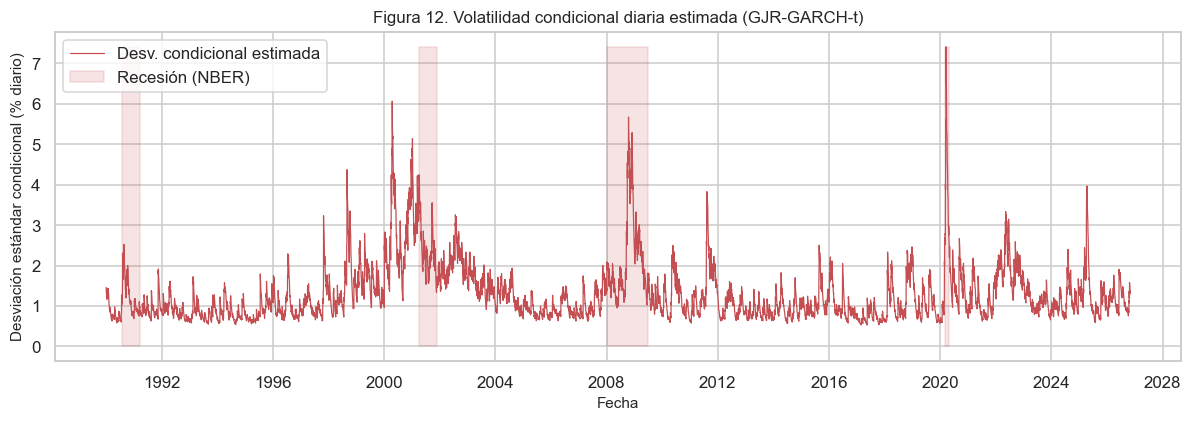

In [51]:
# 4.7.3 Código
print('▼ 4.7.4 Resultado')
def gjr_sigma2(x, omega, alpha, gamma, beta, s0):
    xs = x.tolist(); s2 = [s0] * (len(xs) + 1)
    for t in range(len(xs)):
        e = xs[t]; s2[t + 1] = omega + (alpha + (gamma if e < 0 else 0.0)) * e * e + beta * s2[t]
    return np.array(s2)

def gjr_nll(p, r):
    mu, omega, alpha, gamma, beta, nu = p
    if omega <= 0 or alpha < 0 or gamma < 0 or beta < 0 or nu <= 2.1 or alpha + .5 * gamma + beta >= .9999: return 1e12
    x = r - mu; s2 = gjr_sigma2(x, omega, alpha, gamma, beta, r.var())[:-1]
    ll = gammaln((nu + 1) / 2) - gammaln(nu / 2) - .5 * np.log(np.pi * (nu - 2)) - .5 * np.log(s2) - (nu + 1) / 2 * np.log1p(x * x / (s2 * (nu - 2)))
    return -ll.sum()

def fit_gjr(r, start=None, asym=True):
    v = r.var(); x0 = np.array(start if start is not None else [r.mean(), .05 * v, .03, .08 if asym else 0., .88, 8.])
    bnds = [(-1, 1), (1e-6, None), (0, 1), (0, 1) if asym else (0, 0), (0, 1), (2.1, 100)]
    cons = [{"type": "ineq", "fun": lambda p: .9999 - (p[2] + .5 * p[3] + p[4])}]
    res = optimize.minimize(gjr_nll, x0, args=(r,), method="SLSQP", bounds=bnds, constraints=cons, options={"maxiter": 300, "ftol": 1e-9})
    return res.x, res.fun, res.success

r = work["ret"].values
p_g, nll_g, ok_g = fit_gjr(r, asym=False); p_j, nll_j, ok_j = fit_gjr(r, start=p_g.tolist(), asym=True)
tabm = pd.DataFrame({"GARCH(1,1)-t": p_g, "GJR-GARCH(1,1)-t": p_j}, index=["mu", "omega", "alpha", "gamma", "beta", "nu"])
tabm.loc["persistencia"] = [p_g[2] + p_g[4], p_j[2] + .5 * p_j[3] + p_j[4]]; tabm.loc["log-verosimilitud"] = [-nll_g, -nll_j]
n_ = len(r); tabm.loc["AIC"] = [2 * 5 + 2 * nll_g, 2 * 6 + 2 * nll_j]; tabm.loc["BIC"] = [5 * np.log(n_) + 2 * nll_g, 6 * np.log(n_) + 2 * nll_j]
display(tabm.round(4)); tabm.to_csv(os.path.join(RES_DIR, "parametros_garch.csv"))
LR = 2 * (nll_g - nll_j); p_lr = .5 * stats.chi2.sf(max(LR, 0), 1)
print(f"Convergencia: GARCH = {ok_g}, GJR = {ok_j} | razón de verosimilitud de asimetría (gamma = 0): LR = {LR:.1f}, p {p_fmt(p_lr)} (mezcla 50:50 por parámetro en el borde)")
s2f = gjr_sigma2(r - p_j[0], *p_j[1:5], r.var())[:-1]; z = (r - p_j[0]) / np.sqrt(s2f)
lbz, lbz_p = ljung_box(z ** 2, 10); alz, alz_p = arch_lm(z, 5); lbr, lbr_p = ljung_box(r ** 2, 10)
print(f"Residuos estandarizados: Ljung-Box de z^2 p {p_fmt(lbz_p)} | ARCH-LM p {p_fmt(alz_p)}  (antes del modelo: Ljung-Box de ret^2 p {p_fmt(lbr_p)})")
sc_ = np.sqrt((p_j[5] - 2) / p_j[5])
print(f"Calibración dentro de muestra: proporción de residuos por debajo del cuantil t del 5 % = {100 * np.mean(z < stats.t.ppf(.05, p_j[5]) * sc_):.2f} %; del 1 % = {100 * np.mean(z < stats.t.ppf(.01, p_j[5]) * sc_):.2f} % (valores esperados: 5 % y 1 %)")
RES["cal_5"] = float(100 * np.mean(z < stats.t.ppf(.05, p_j[5]) * sc_)); RES["cal_1"] = float(100 * np.mean(z < stats.t.ppf(.01, p_j[5]) * sc_))
fig, ax = plt.subplots(figsize=(11, 4)); ax.plot(work.index, np.sqrt(s2f), lw=.8, color="#C44E52", label="Desv. condicional estimada")
rr = work["rec"].values; ax.fill_between(work.index, 0, np.sqrt(s2f).max(), where=rr == 1, color=COL[1], alpha=.15, label="Recesión (NBER)")
ax.set(title="Figura 12. Volatilidad condicional diaria estimada (GJR-GARCH-t)", xlabel="Fecha", ylabel="Desviación estándar condicional (% diario)"); ax.legend(loc="upper left")
guardar("fig12_volatilidad_condicional.png")
RES["garch"] = dict(alpha=float(p_j[2]), gamma=float(p_j[3]), beta=float(p_j[4]), nu=float(p_j[5]), persist=float(p_j[2] + .5 * p_j[3] + p_j[4]), lr=float(LR), lr_p=float(p_lr), lb_z2_p=float(lbz_p), archlm_z_p=float(alz_p), aic_g=float(tabm.loc["AIC", "GARCH(1,1)-t"]), aic_j=float(tabm.loc["AIC", "GJR-GARCH(1,1)-t"]), ok=bool(ok_j))

**4.7.5 Interpretación.** El término de asimetría es claro: gamma = 0.133 frente a alpha = 0.027 significa que un retorno negativo eleva la varianza del día siguiente unas seis veces más que uno positivo del mismo tamaño (alpha + gamma contra alpha). La razón de verosimilitud (155.1, p < 0.001) y el AIC (28,841.8 frente a 28,994.9 del GARCH simétrico) respaldan el modelo asimétrico. La persistencia es 0.985: los choques de volatilidad se disipan lentamente (vida media de unos 46 días hábiles). Los grados de libertad de la t son 8.2, lo que confirma colas pesadas. El diagnóstico es favorable: tras el modelo, los residuos estandarizados ya no muestran efectos ARCH (Ljung-Box de z² p = 0.163; ARCH-LM p = 0.147), mientras que los retornos originales sí (p < 0.001): el modelo capturó el agrupamiento. La figura muestra la volatilidad condicional subiendo en 2000-2002, 2008-2009 y 2020. **Una advertencia:** la calibración de los cuantiles t no es perfecta dentro de la muestra: el 6.41 % de los días cae bajo el cuantil del 5 % (esperado 5 %) y el 1.28 % bajo el del 1 %. Esto anticipa un VaR algo corto, sobre todo al 95 %.

### 4.8 Extensión avanzada B: VaR y ES de un día con ventana móvil (histórico, normal y GJR-GARCH-t)

**4.8.1 Descripción.** Para cada día desde el 1001.º se estiman, solo con los 1,000 retornos anteriores, el VaR y el ES al 95 % y al 99 % con tres modelos: **histórico** (percentil empírico de las pérdidas, sin suponer forma), **normal** (media y desviación de la ventana) y **GJR-GARCH-t** (se reestima cada 63 días y la varianza se actualiza a diario). El VaR es la pérdida que se espera superar solo con probabilidad 1 - nivel; el ES es la pérdida promedio cuando se supera. Las pérdidas son los retornos con signo cambiado.

**4.8.2 Calcular las previsiones diarias de VaR y ES de los tres modelos con ventana móvil**

In [52]:
# 4.8.3 Código
print('▼ 4.8.4 Resultado')
def var_es_t(mu, sig, nu, a):
    pp = 1 - a; tp = stats.t.ppf(pp, nu); sc = np.sqrt((nu - 2) / nu)
    return -(mu + sig * sc * tp), -mu + sig * sc * (stats.t.pdf(tp, nu) / pp) * ((nu + tp ** 2) / (nu - 1))

MOD = ["Histórico", "Normal", "GJR-GARCH-t"]
def rolling_risk(rv, window, alphas, refit=REFIT):
    n = len(rv); T = n - window
    out = {(m, a, k): np.full(T, np.nan) for m in MOD for a in alphas for k in ("VaR", "ES")}; gp = None
    for i, t in enumerate(range(window, n)):
        w = rv[t - window:t]; l = -w
        for a in alphas:
            v = np.quantile(l, a); out[("Histórico", a, "VaR")][i] = v; out[("Histórico", a, "ES")][i] = l[l >= v].mean()
            m_, s_ = w.mean(), w.std(ddof=1); zq = stats.norm.ppf(a)
            out[("Normal", a, "VaR")][i] = -m_ + s_ * zq; out[("Normal", a, "ES")][i] = -m_ + s_ * stats.norm.pdf(zq) / (1 - a)
        if i % refit == 0:
            pr_, _, ok = fit_gjr(w, start=None if gp is None else gp.tolist()); gp = pr_ if ok or gp is None else gp
        mu, om, al, ga, be, nu = gp; sg = np.sqrt(gjr_sigma2(w - mu, om, al, ga, be, w.var())[-1])
        for a in alphas:
            vv, ee = var_es_t(mu, sg, nu, a); out[("GJR-GARCH-t", a, "VaR")][i] = vv; out[("GJR-GARCH-t", a, "ES")][i] = ee
    return out

t0 = time.time(); OUT = rolling_risk(r, WINDOW, NIVELES)
loss_oos, dates_oos, rec_oos = -r[WINDOW:], work.index[WINDOW:], work["rec"].values[WINDOW:]
print(f"Cálculo listo en {time.time() - t0:.0f} s | días fuera de muestra: {len(loss_oos)} ({dates_oos[0].date()} a {dates_oos[-1].date()}) | ventana = {WINDOW}")
print(f"Días de recesión fuera de muestra: {int(rec_oos.sum())} ({100 * rec_oos.mean():.1f} %)")
diario = pd.DataFrame({"perdida": loss_oos, "rec": rec_oos}, index=dates_oos)
for (m, a, k), v in OUT.items(): diario[f"{m}_{int(a * 100)}_{k}"] = v
diario.to_csv(os.path.join(RES_DIR, "var_es_diario.csv"))
display(diario.filter(like="_99_VaR").describe().round(2))
RES.update(bt_T=int(len(loss_oos)), bt_ini=str(dates_oos[0].date()), pct_dias_rec_oos=float(100 * rec_oos.mean()))

▼ 4.8.4 Resultado
Cálculo listo en 20 s | días fuera de muestra: 8276 (1993-12-15 a 2026-10-30) | ventana = 1000
Días de recesión fuera de muestra: 586 (7.1 %)


,Histórico_99_VaR,Normal_99_VaR,GJR-GARCH-t_99_VaR
count,8276.00,8276.00,8276.00
mean,3.86,3.25,3.19
std,1.23,1.14,1.82
min,2.18,1.70,1.26
25%,2.78,2.27,1.91
50%,3.63,3.17,2.64
75%,4.98,3.98,3.88
max,6.37,5.84,21.96


**4.8.5 Interpretación.** Quedan 8,276 días fuera de muestra (del 15-dic-1993 al 30-oct-2026), de los cuales 586 (7.1 %) son de recesión, correspondientes a 2001, 2008-2009 y 2020; la recesión de 1990-1991 queda dentro de la primera ventana y no se evalúa. El VaR al 99 % medio es parecido en los tres modelos (3.86 %, 3.25 % y 3.19 %), pero su comportamiento difiere: el histórico y el normal cambian lentamente porque promedian 1,000 días, mientras que el GJR-GARCH-t reacciona día a día (de 1.26 % a 21.96 %). Los valores diarios se guardan en `resultados/var_es_diario.csv`.

## 5. Evaluación

### 5.1 Backtesting de VaR: pruebas de Kupiec y Christoffersen

**5.1.1 Descripción.** Un día es una **excepción** si la pérdida supera el VaR pronosticado. Si el modelo es correcto, la frecuencia de excepciones debe ser 1 - nivel (5 % o 1 %) y las excepciones no deben venir en rachas. **Kupiec** (cobertura incondicional): H0 = la tasa de excepciones es 1 - nivel. **Christoffersen** (independencia): H0 = la probabilidad de excepción hoy no depende de si hubo una ayer. Se rechaza H0 si p < 0.05. Un modelo es *utilizable* (C3) si no se rechaza ninguna de las dos pruebas en ambos niveles. Con pocas excepciones (99 %) las pruebas tienen baja potencia.

**5.1.2 Contar excepciones y aplicar Kupiec y Christoffersen a cada modelo y nivel**

In [53]:
# 5.1.3 Código
print('▼ 5.1.4 Resultado')
def kupiec(I, p):
    T, x = len(I), int(I.sum())
    ll0 = (T - x) * np.log(1 - p) + xlogy(x, p); ll1 = xlogy(T - x, 1 - x / T) + xlogy(x, x / T)
    lr = -2 * (ll0 - ll1); return lr, stats.chi2.sf(lr, 1)

def christoffersen(I, p):
    a, b = I[:-1].astype(int), I[1:].astype(int)
    n00, n01, n10, n11 = ((a == 0) & (b == 0)).sum(), ((a == 0) & (b == 1)).sum(), ((a == 1) & (b == 0)).sum(), ((a == 1) & (b == 1)).sum()
    pi = (n01 + n11) / max(n00 + n01 + n10 + n11, 1); pi01 = n01 / max(n00 + n01, 1); pi11 = n11 / max(n10 + n11, 1)
    ll0 = xlogy(n00 + n10, 1 - pi) + xlogy(n01 + n11, pi); ll1 = xlogy(n00, 1 - pi01) + xlogy(n01, pi01) + xlogy(n10, 1 - pi11) + xlogy(n11, pi11)
    lr_ind = max(-2 * (ll0 - ll1), 0); lr_pof, _ = kupiec(I, p)
    return lr_ind, stats.chi2.sf(lr_ind, 1), lr_pof + lr_ind, stats.chi2.sf(lr_pof + lr_ind, 2)

rows = []; p0 = float(np.mean(rec_oos == 1))
for m in MOD:
    for a in NIVELES:
        v, e = OUT[(m, a, "VaR")], OUT[(m, a, "ES")]; I = (loss_oos > v).astype(int); p = 1 - a
        lk, pk = kupiec(I, p); li, pi_, lc, pc = christoffersen(I, p)
        k_rec, n_exc = int(I[rec_oos == 1].sum()), int(I.sum())
        rows.append(dict(modelo=m, nivel=a, T=len(I), esperadas=round(p * len(I), 1), observadas=n_exc, tasa_pct=100 * I.mean(), kupiec_p=pk, christoffersen_p=pi_, cobertura_cond_p=pc,
                         exc_en_recesion=k_rec, pct_exc_recesion=(100 * k_rec / n_exc if n_exc else np.nan), pct_dias_recesion=100 * p0,
                         binomial_p=(stats.binomtest(k_rec, n_exc, p0).pvalue if n_exc else np.nan),
                         ES_pronosticado_en_excepciones=(float(e[I == 1].mean()) if n_exc else np.nan), perdida_media_en_excepciones=(float(loss_oos[I == 1].mean()) if n_exc else np.nan)))
bt = pd.DataFrame(rows); bt.to_csv(os.path.join(RES_DIR, "backtest.csv"), index=False)
vista = bt[["modelo", "nivel", "T", "esperadas", "observadas", "tasa_pct", "kupiec_p", "christoffersen_p"]].copy()
vista["tasa_pct"] = vista["tasa_pct"].round(2); vista["kupiec_p"] = vista["kupiec_p"].round(4); vista["christoffersen_p"] = vista["christoffersen_p"].round(4)
vista["¿rechaza Kupiec o Christoffersen? (p < 0.05)"] = np.where((bt["kupiec_p"] < ALPHA) | (bt["christoffersen_p"] < ALPHA), "sí", "no")
display(vista)
ut = bt.groupby("modelo").apply(lambda g: bool(((g["kupiec_p"] >= ALPHA) & (g["christoffersen_p"] >= ALPHA)).all())).reindex(MOD)
print("¿Modelo utilizable según C3 (no se rechaza ninguna prueba en ambos niveles)?"); display(ut.rename("utilizable"))
RES["c3"] = {m: bool(v) for m, v in ut.items()}

▼ 5.1.4 Resultado


,modelo,nivel,T,esperadas,observadas,tasa_pct,kupiec_p,christoffersen_p,¿rechaza Kupiec o Christoffersen? (p < 0.05)
0,Histórico,0.95,8276,413.8,488,5.90,0.0003,0.0000,sí
1,Histórico,0.99,8276,82.8,131,1.58,0.0000,0.0000,sí
2,Normal,0.95,8276,413.8,491,5.93,0.0002,0.0000,sí
3,Normal,0.99,8276,82.8,227,2.74,0.0000,0.0001,sí
4,GJR-GARCH-t,0.95,8276,413.8,535,6.46,0.0000,0.1566,sí
5,GJR-GARCH-t,0.99,8276,82.8,131,1.58,0.0000,0.5395,sí


¿Modelo utilizable según C3 (no se rechaza ninguna prueba en ambos niveles)?


modelo
Histórico      False
Normal         False
GJR-GARCH-t    False
Name: utilizable, dtype: bool

**5.1.5 Interpretación.** Con 8,276 días se esperarían 413.8 excepciones al 95 % y 82.8 al 99 %. Se observaron 488, 491 y 535 al 95 % (histórico, normal y GJR-GARCH-t) y 131, 227 y 131 al 99 %. Kupiec rechaza los tres modelos en ambos niveles (todos p < 0.001): los tres subestiman el riesgo. El normal es el peor al 99 % (2.74 % de excepciones, casi tres veces lo esperado). Christoffersen rechaza la independencia del histórico y del normal en ambos niveles (p < 0.001), pero **no** la del GJR-GARCH-t (p = 0.157 al 95 % y 0.540 al 99 %): sus excepciones no vienen en rachas, que es justo lo que el modelo busca corregir. Según C3 **ningún modelo es utilizable**. Con tantos días la prueba tiene mucha potencia, así que desviaciones moderadas (1.58 % frente a 1 %) ya se rechazan; el hallazgo es que ninguno es calibrado, aunque el GJR-GARCH-t es el mejor en independencia.

### 5.2 Comportamiento de las excepciones en recesión (C4) y evaluación descriptiva del ES

**5.2.1 Descripción.** **Pregunta:** ¿se concentran las excepciones en los días de recesión más de lo que corresponde? **H0:** la proporción de excepciones que ocurren en recesión es igual a la proporción de días de recesión del período evaluado; **H1:** es distinta. Se aplica una prueba binomial exacta por modelo y nivel. Como el ES no tiene aquí una prueba formal, se compara de forma descriptiva el ES pronosticado medio con la pérdida media observada en los días de excepción.

**5.2.2 Aplicar la prueba binomial por estado del ciclo y graficar VaR, excepciones acumuladas y recesiones**

▼ 5.2.4 Resultado


,modelo,nivel,observadas,exc_en_recesion,pct_exc_recesion,pct_dias_recesion,binomial_p
0,Histórico,0.95,488,89,18.2,7.1,< 0.001
1,Histórico,0.99,131,40,30.5,7.1,< 0.001
2,Normal,0.95,491,87,17.7,7.1,< 0.001
3,Normal,0.99,227,54,23.8,7.1,< 0.001
4,GJR-GARCH-t,0.95,535,51,9.5,7.1,0.034
5,GJR-GARCH-t,0.99,131,11,8.4,7.1,0.497


,modelo,nivel,ES_pronosticado_en_excepciones,perdida_media_en_excepciones,diferencia (real - pronosticado)
0,Histórico,0.95,3.11,3.20,0.09
1,Histórico,0.99,4.54,4.59,0.05
2,Normal,0.95,2.55,3.14,0.59
3,Normal,0.99,3.23,3.98,0.75
4,GJR-GARCH-t,0.95,2.63,2.70,0.07
5,GJR-GARCH-t,0.99,3.20,3.27,0.07


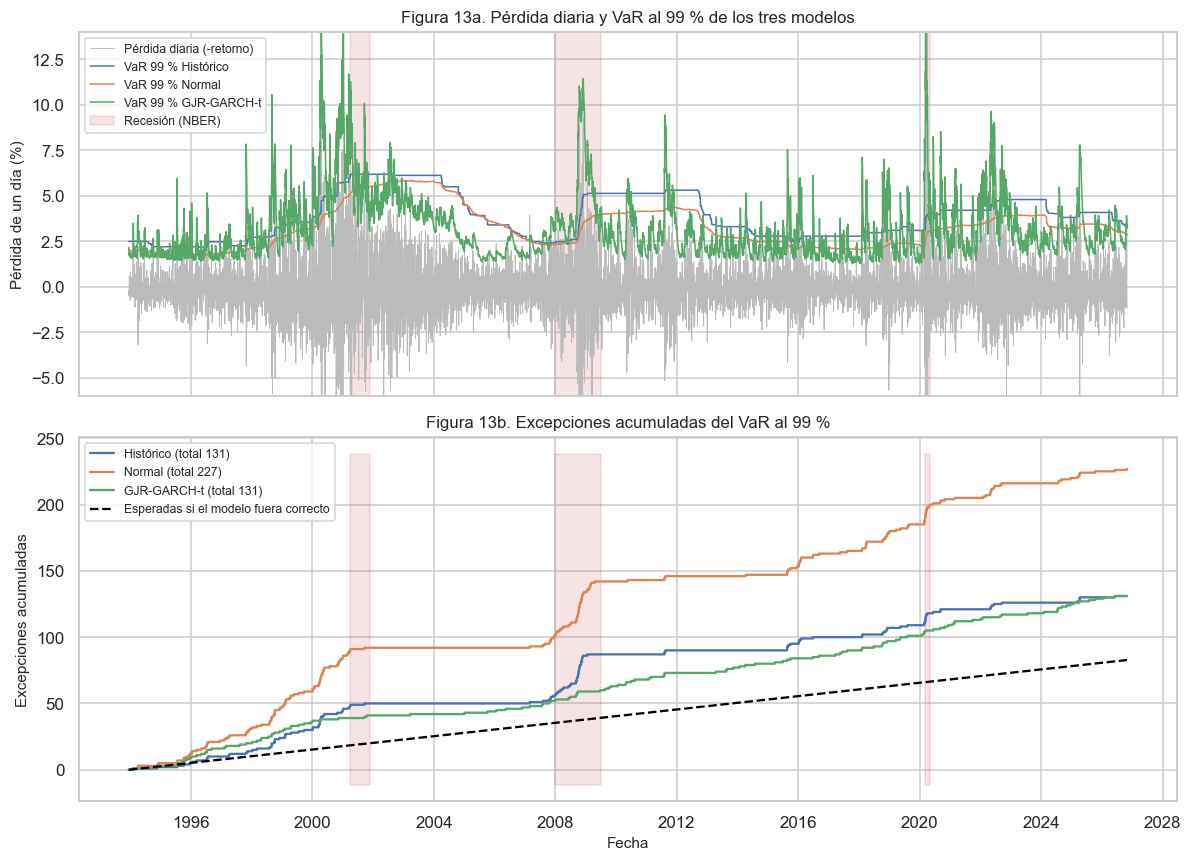

In [54]:
# 5.2.3 Código
print('▼ 5.2.4 Resultado')
c4 = bt[["modelo", "nivel", "observadas", "exc_en_recesion", "pct_exc_recesion", "pct_dias_recesion", "binomial_p"]].copy()
c4["pct_exc_recesion"] = c4["pct_exc_recesion"].round(1); c4["pct_dias_recesion"] = c4["pct_dias_recesion"].round(1); c4["binomial_p"] = c4["binomial_p"].map(lambda x: "" if pd.isna(x) else p_fmt(x))
display(c4)
es = bt[["modelo", "nivel", "ES_pronosticado_en_excepciones", "perdida_media_en_excepciones"]].round(2); es["diferencia (real - pronosticado)"] = (es["perdida_media_en_excepciones"] - es["ES_pronosticado_en_excepciones"]).round(2); display(es)
RES["c4"] = {f"{r_.modelo}_{int(r_.nivel * 100)}": dict(p=(None if np.isnan(r_.binomial_p) else float(r_.binomial_p)), exc=int(r_.observadas), exc_rec=int(r_.exc_en_recesion)) for r_ in bt.itertuples()}
col = {"Histórico": "#4C72B0", "Normal": "#DD8452", "GJR-GARCH-t": "#55A868"}
fig, ax = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
ax[0].plot(dates_oos, loss_oos, color="#BBBBBB", lw=.6, label="Pérdida diaria (-retorno)")
for m in MOD: ax[0].plot(dates_oos, OUT[(m, 0.99, "VaR")], lw=1, color=col[m], label=f"VaR 99 % {m}")
ax[0].set(title="Figura 13a. Pérdida diaria y VaR al 99 % de los tres modelos", ylabel="Pérdida de un día (%)", ylim=(-6, 14))
for m in MOD:
    I = (loss_oos > OUT[(m, 0.99, "VaR")]).astype(int); ax[1].step(dates_oos, I.cumsum(), where="post", color=col[m], label=f"{m} (total {int(I.sum())})")
ax[1].plot(dates_oos, 0.01 * np.arange(1, len(dates_oos) + 1), color="black", ls="--", label="Esperadas si el modelo fuera correcto")
ax[1].set(title="Figura 13b. Excepciones acumuladas del VaR al 99 %", xlabel="Fecha", ylabel="Excepciones acumuladas")
for a_ in ax:
    a_.fill_between(dates_oos, *a_.get_ylim(), where=rec_oos == 1, color=COL[1], alpha=.15, label="Recesión (NBER)" if a_ is ax[0] else None); a_.legend(loc="upper left", fontsize=8)
guardar("fig13_var_excepciones.png")

**5.2.5 Interpretación.** Las excepciones del histórico y del normal se concentran en las recesiones: al 99 %, el 30.5 % (40 de 131) y el 23.8 % (54 de 227) ocurren en recesión, frente al 7.1 % de los días (p < 0.001 en ambos); al 95 %, el 18.2 % y el 17.7 %. En el GJR-GARCH-t al 99 % hay 11 de 131 (8.4 %), cercano al 7.1 % (p = 0.497): no hay desproporción. Al 95 % es 9.5 % (p = 0.034), ligeramente alta. La figura 13b lo muestra: las excepciones del histórico y del normal saltan en 2000-2001, 2008-2009 y 2020, mientras que el GJR-GARCH-t avanza de forma más pareja. Sobre el ES (descriptivo, no es una prueba): la pérdida media en los días de excepción es casi igual al ES pronosticado en esos días para el histórico (+0.05 a +0.09 puntos) y el GJR-GARCH-t (+0.07), y lo supera en 0.59 a 0.75 puntos para el normal, que subestima la severidad de las pérdidas extremas. Así, C4 se cumple solo para el GJR-GARCH-t al 99 %.

### 5.3 Robustez: repetir el contraste con la muestra recortada al 31-dic-2024

**5.3.1 Descripción.** El archivo `USREC` no distingue los meses recientes aún sin clasificar por el NBER, que figuran como expansión. Para ver si eso altera la conclusión, se repiten las pruebas de C1 y la razón de volatilidades con la muestra hasta el 31 de diciembre de 2024.

**5.3.2 Repetir Welch, Mann-Whitney y la razón de volatilidades con la muestra recortada**

In [55]:
# 5.3.3 Código
print('▼ 5.3.4 Resultado')
w2 = work.loc[:CORTE_ROBUSTEZ]; m2 = mensual(w2); R2 = c1(m2); RZ2 = razon_boot(w2)
comp = pd.DataFrame({"Muestra completa": [int(R["n_rec"] + R["n_exp"]), f"{R['dif']:.3f}", f"[{R['ic_lo']:.2f}, {R['ic_hi']:.2f}]", p_fmt(R["p_welch"]), p_fmt(R["p_mw"]), f"{RZ['razon']:.2f}", f"[{RZ['lo']:.2f}, {RZ['hi']:.2f}]"],
                     f"Hasta {CORTE_ROBUSTEZ}": [int(R2["n_rec"] + R2["n_exp"]), f"{R2['dif']:.3f}", f"[{R2['ic_lo']:.2f}, {R2['ic_hi']:.2f}]", p_fmt(R2["p_welch"]), p_fmt(R2["p_mw"]), f"{RZ2['razon']:.2f}", f"[{RZ2['lo']:.2f}, {RZ2['hi']:.2f}]"]},
                    index=["Meses", "Diferencia de log-volatilidad", "IC 95 % de la diferencia", "p (Welch)", "p (Mann-Whitney)", "Razón de volatilidades diarias", "IC 95 % de la razón"])
display(comp)
mismo = (R["p_welch"] < ALPHA) == (R2["p_welch"] < ALPHA) and (R["p_mw"] < ALPHA) == (R2["p_mw"] < ALPHA) and (RZ["lo"] > 1) == (RZ2["lo"] > 1)
print("¿Misma conclusión en C1 con la muestra recortada?", "sí" if mismo else "no")
RES["robustez"] = dict(p_welch=float(R2["p_welch"]), p_mw=float(R2["p_mw"]), razon=RZ2["razon"], lo=RZ2["lo"], hi=RZ2["hi"], misma=bool(mismo))

▼ 5.3.4 Resultado


,Muestra completa,Hasta 2024-12-31
Meses,442,420
Diferencia de log-volatilidad,0.604,0.609
IC 95 % de la diferencia,"[0.43, 0.78]","[0.43, 0.78]"
p (Welch),< 0.001,< 0.001
p (Mann-Whitney),< 0.001,< 0.001
Razón de volatilidades diarias,1.82,1.83
IC 95 % de la razón,"[1.46, 2.18]","[1.46, 2.20]"


¿Misma conclusión en C1 con la muestra recortada? sí


**5.3.5 Interpretación.** Al recortar la muestra al 31-dic-2024 el resultado no cambia: diferencia de log-volatilidad 0.609 frente a 0.604, mismo IC [0.43, 0.78], p < 0.001 en ambas pruebas, y razón de volatilidades 1.83 [1.46, 2.20] frente a 1.82 [1.46, 2.18]. Esto era de esperar porque el recorte solo quita 22 meses de expansión. Muestra que la conclusión no depende de cómo se traten los meses recientes de `USREC`, aunque no resuelve que estén sin clasificar.

### 5.4 Comparación de resultados y tamaños del efecto

**5.4.1 Descripción.** Se reúnen en una sola tabla las pruebas realizadas, su estadístico, su valor p y su tamaño del efecto, para comparar métodos: lo significativo se distingue de lo relevante en magnitud.

**5.4.2 Consolidar pruebas, valores p y tamaños del efecto**

In [56]:
# 5.4.3 Código
print('▼ 5.4.4 Resultado')
sp, ch, ol = RES["spearman"], RES["chi2"], RES["ols"]
tab = pd.DataFrame([
 ["Spearman |ret| ~ VIX(t-1)", "Bivariado", f"rho = {sp['rho']:.3f}", sp["p"], "rho (monótona)", sp["rho"]],
 ["Chi-cuadrado régimen VIX x día de baja", "Bivariado", f"chi2 = {ch['chi2']:.1f}", ch["p"], "V de Cramér", ch["V"]],
 ["Regresión ret ~ dVIX (Newey-West)", "Bivariado / paramétrica", f"t = {ol['t']:.1f}", ol["p"], "R2", ol["r2"]],
 ["t de Welch, log-volatilidad mensual", "Paramétrica", f"t = {R['t']:.2f}", R["p_welch"], "d de Cohen", R["d"]],
 ["Control Newey-West (recesión)", "Paramétrica", f"b = {R['b_hac']:.3f}", R["p_hac"], "diferencia de log-vol.", R["b_hac"]],
 ["Mann-Whitney, log-volatilidad mensual", "No paramétrica", f"U = {R['U']:.0f}", R["p_mw"], "CLES (prob. superioridad)", R["cles"]],
 ["Razón de volatilidades diarias", "Magnitud (C2)", f"IC [{RZ['lo']:.2f}, {RZ['hi']:.2f}]", np.nan, "razón", RZ["razon"]],
], columns=["Análisis", "Tipo", "Estadístico", "Valor p", "Tamaño del efecto", "Valor"])
tab["Valor p"] = tab["Valor p"].map(lambda x: "" if pd.isna(x) else p_fmt(x)); tab["Valor"] = tab["Valor"].round(3)
display(tab); tab.to_csv(os.path.join(RES_DIR, "comparacion_pruebas.csv"), index=False)

▼ 5.4.4 Resultado


,Análisis,Tipo,Estadístico,Valor p,Tamaño del efecto,Valor
0,Spearman |ret| ~ VIX(t-1),Bivariado,rho = 0.385,< 0.001,rho (monótona),0.385
1,Chi-cuadrado régimen VIX x día de baja,Bivariado,chi2 = 1.9,0.378,V de Cramér,0.014
2,Regresión ret ~ dVIX (Newey-West),Bivariado / paramétrica,t = -30.7,< 0.001,R2,0.491
3,"t de Welch, log-volatilidad mensual",Paramétrica,t = 6.99,< 0.001,d de Cohen,1.265
4,Control Newey-West (recesión),Paramétrica,b = 0.604,< 0.001,diferencia de log-vol.,0.604
5,"Mann-Whitney, log-volatilidad mensual",No paramétrica,U = 11880,< 0.001,CLES (prob. superioridad),0.813
6,Razón de volatilidades diarias,Magnitud (C2),"IC [1.46, 2.18]",,razón,1.824


**5.4.5 Interpretación.** La tabla separa significancia de relevancia. El chi-cuadrado de régimen de VIX y día de baja no es significativo (V = 0.014, efecto despreciable). El Spearman (0.385) y la regresión con el cambio del VIX (R² = 0.49) son significativos y de tamaño moderado a grande. El contraste de volatilidad entre recesión y expansión es significativo con ambos métodos, y su efecto es grande (d de Cohen = 1.27; probabilidad de superioridad 0.81; razón de volatilidades 1.82). Las pruebas paramétrica y no paramétrica coinciden, y el control con errores robustos mantiene la conclusión (con una incertidumbre mayor).

### 5.5 Verificación de los criterios de éxito

**5.5.1 Descripción.** Se aplican, de forma automática y sin cambiar las reglas, los criterios C1 a C4 fijados antes de ver resultados.

**5.5.2 Evaluar C1 a C4 con las reglas fijadas y guardar las métricas**

In [57]:
# 5.5.3 Código
print('▼ 5.5.4 Resultado')
c1_ok = bool(R["p_welch"] < ALPHA and R["p_mw"] < ALPHA and (R["ic_lo"] > 0 or R["ic_hi"] < 0))
print(f"C1 (significancia): Welch p {p_fmt(R['p_welch'])}, Mann-Whitney p {p_fmt(R['p_mw'])}, IC 95 % de la diferencia [{R['ic_lo']:.2f}, {R['ic_hi']:.2f}] -> {'CUMPLE' if c1_ok else 'NO CUMPLE'}")
print(f"C2 (relevancia): razón {RZ['razon']:.2f}, IC [{RZ['lo']:.2f}, {RZ['hi']:.2f}] -> umbrales superados: {[u for u in UMBRALES if RZ['lo'] > u] or 'ninguno'}; umbral de quiebre = {RZ['lo']:.2f}")
print("C3 (modelo utilizable):", {m: ("sí" if v else "no") for m, v in RES["c3"].items()})
print("C4 (excepciones en recesión; binomial p < 0.05 = desproporción):")
c4_ok = {}
for k, v in RES["c4"].items():
    c4_ok[k] = (v["p"] is not None) and v["p"] >= ALPHA; print(f"   {k}: {v['exc_rec']} de {v['exc']} excepciones en recesión, p {'n/d' if v['p'] is None else p_fmt(v['p'])} -> {'sin desproporción' if c4_ok[k] else 'desproporción (o sin excepciones)'}")
RES["criterios"] = dict(C1=c1_ok, C2_umbral_quiebre=RZ["lo"], C3=RES["c3"], C4=c4_ok)
def conv(o):
    if isinstance(o, dict): return {str(k): conv(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [conv(v) for v in o]
    if isinstance(o, (np.bool_, bool)): return bool(o)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating, float)): return float(o)
    return o
json.dump(conv(RES), open(os.path.join(RES_DIR, "metricas.json"), "w"), ensure_ascii=False, indent=1)
print("\nMétricas guardadas en", os.path.join(RES_DIR, "metricas.json"))

▼ 5.5.4 Resultado
C1 (significancia): Welch p < 0.001, Mann-Whitney p < 0.001, IC 95 % de la diferencia [0.43, 0.78] -> CUMPLE
C2 (relevancia): razón 1.82, IC [1.46, 2.18] -> umbrales superados: [1.1, 1.25]; umbral de quiebre = 1.46
C3 (modelo utilizable): {'Histórico': 'no', 'Normal': 'no', 'GJR-GARCH-t': 'no'}
C4 (excepciones en recesión; binomial p < 0.05 = desproporción):
   Histórico_95: 89 de 488 excepciones en recesión, p < 0.001 -> desproporción (o sin excepciones)
   Histórico_99: 40 de 131 excepciones en recesión, p < 0.001 -> desproporción (o sin excepciones)
   Normal_95: 87 de 491 excepciones en recesión, p < 0.001 -> desproporción (o sin excepciones)
   Normal_99: 54 de 227 excepciones en recesión, p < 0.001 -> desproporción (o sin excepciones)
   GJR-GARCH-t_95: 51 de 535 excepciones en recesión, p 0.034 -> desproporción (o sin excepciones)
   GJR-GARCH-t_99: 11 de 131 excepciones en recesión, p 0.497 -> sin desproporción

Métricas guardadas en resultados/metricas.json


**5.5.5 Interpretación.** **C1 se cumple**: Welch y Mann-Whitney dan p < 0.001 y el IC 95 % de la diferencia es [0.43, 0.78]. **C2**: la razón de volatilidades es 1.82 [1.46, 2.18]; se superan los umbrales 1.10 y 1.25, no el 1.50 (umbral de quiebre 1.46) ni el 2.00. **C3 no se cumple** para ningún modelo (Kupiec los rechaza a todos). **C4** solo se cumple para el GJR-GARCH-t al 99 % (p = 0.497); no se cumple al 95 % (p = 0.034) ni para el histórico y el normal.

### 5.6 Conclusiones, recomendaciones y limitaciones

**Hallazgos principales**

1. **El riesgo de mercado del NASDAQ es claramente mayor en recesión.** La volatilidad mensual es 1.83 veces mayor (Welch p < 0.001; Mann-Whitney p < 0.001; probabilidad de superioridad 0.81). La volatilidad diaria es 1.82 veces mayor, con IC 95 % [1.46, 2.18]: es al menos 46 % mayor con 95 % de confianza. Significa que, en recesión, las pérdidas de un día son sustancialmente más grandes (VaR histórico al 99 %: 6.55 % frente a 3.88 %). *Recomendación:* en una recesión declarada o probable, los límites de riesgo deberían revisarse al alza con un factor cercano a 1.5 (el límite inferior del IC es 1.46) y no mantenerse al nivel de los períodos tranquilos. Como el NBER fecha las recesiones con retraso, esa alerta tendría que apoyarse en indicadores oportunos, como el VIX (hallazgo 5).

2. **Los retornos no son normales y la volatilidad se agrupa.** Curtosis en exceso de 6.65, Jarque-Bera p < 0.001, y efectos ARCH muy marcados. *Recomendación:* no usar métodos que supongan normalidad o varianza constante; el modelo normal subestimó las excepciones al 99 % en casi tres veces (2.74 % frente al 1 % esperado).

3. **Ningún modelo de VaR probado cumple todos los criterios de calibración.** Kupiec rechaza a los tres en ambos niveles. El histórico y el normal además presentan excepciones en rachas y concentradas en recesión (30.5 % y 23.8 % de sus excepciones al 99 % frente al 7.1 % de los días). *Recomendación:* para el ES y el VaR al 99 %, preferir un modelo de volatilidad condicional frente a los de ventana fija.

4. **El GJR-GARCH-t es el modelo más adecuado de los tres, aunque no perfecto.** Sus excepciones son independientes (Christoffersen p = 0.157 y 0.540) y, al 99 %, proporcionales al ciclo (8.4 % frente al 7.1 %, p = 0.497); su ES coincide con la pérdida real en las excepciones (+0.07 puntos). Pero se queda corto en la frecuencia (1.58 % de excepciones al 99 % y 6.46 % al 95 %). *Recomendación:* usarlo como base y recalibrar sus cuantiles (por ejemplo con los residuos estandarizados empíricos en lugar de la t), alternativa que no se probó aquí.

5. **El VIX se asocia con la magnitud del movimiento, no con su dirección.** Spearman 0.385 entre |retorno| y el VIX del día anterior; chi-cuadrado sin asociación entre el régimen de VIX y los días de baja (V = 0.014); y un cambio contemporáneo del VIX explica el 49 % de la variabilidad del retorno (b = −0.61). *Recomendación:* el VIX sirve como indicador de alerta del nivel de riesgo, no como señal de dirección.

**Limitaciones**

- **Pocos episodios.** Solo hay cuatro recesiones (tres en el backtesting). Los 36 meses de recesión no son 36 observaciones independientes; los intervalos son más anchos de lo que sugiere Welch. No se probó si el resultado se repite en cada episodio por separado.
- **Dependencia temporal.** La volatilidad mensual tiene autocorrelación de 0.70 y los días no son independientes en varianza; se usaron errores de Newey-West y el mes como unidad, pero los valores p de las pruebas diarias son orientativos.
- **Definición de recesión.** El fechado del NBER es retrospectivo y no coincide con los episodios de estrés bursátil (la caída de 2000-2002 empezó antes de la recesión de 2001; 2022 y abril de 2025 figuran como expansión). Los meses recientes de `USREC` no pueden distinguirse de "sin clasificar"; la robustez al 31-dic-2024 no cambió el resultado.
- **Modelos.** El GJR-GARCH-t se reestima cada 63 días con una ventana de 1,000; su t se calibra mal en el 5 % (6.41 % dentro de muestra). No se probó EVT, la distribución empírica de residuos ni una prueba formal de ES. La evaluación del ES fue solo descriptiva.
- **Alcance.** Un solo índice, un horizonte de un día y sin carteras. Los terciles del VIX usan información de toda la muestra.
- **Causalidad.** Los resultados son asociaciones y diferencias estadísticas; no demuestran que la recesión cause la mayor volatilidad (ni que el VIX cause los movimientos del índice).

**Trabajo futuro:** EVT, prueba formal de ES, otros índices (S&P 500, NASDAQ-100) y robustez con otras ventanas.

In [58]:
print("Notebook ejecutado de principio a fin.")
print("Archivos generados en 'figuras' y 'resultados':", len(os.listdir(FIG_DIR)), "figuras y", len(os.listdir(RES_DIR)), "tablas/archivos")

Notebook ejecutado de principio a fin.
Archivos generados en 'figuras' y 'resultados': 13 figuras y 10 tablas/archivos
